# Домашнее задание 4. Конвейер на потоке
## Детекция, трекинг, перенос между доменами и сборка системы

Проект завершается. В предыдущих заданиях вы подготовили данные, обучили классификатор документов и экстрактор таблиц. Теперь документы поступают не как готовые сканы, а как видеопоток с камеры над рабочим местом.

> **Пятница, 17:30. Финальное письмо заказчика.**  
> «Оператор кладет на стол один или несколько документов. Иногда лист движется быстро, перекрывается рукой, исчезает на несколько кадров или другой документ появляется в том же месте. Нам нужен итог за смену: сколько физических документов прошло, каких они типов и какие таблицы удалось извлечь.»

### Что положить в `/content`

1. **`dz4_video.zip`** — новый единый видеонабор со схемой v2: 48 fit-клипов, 16 development-клипов и 20 скрытых test-клипов.
2. **`dz2_artifacts.zip`** — ваш артефакт классификатора из ДЗ 2.
3. **`dz3_artifacts.zip`** — ваш артефакт U-Net из ДЗ 3.

Преподаватель дополнительно может положить **`dz4_test_answers.csv`**. Студентам этот файл не выдается и при обучении или подборе параметров не используется.

### Что будет новым в ДЗ 4

- обучение YOLO для поиска листа в полном видеокадре;
- трекинг физических документов через движение, перекрытия и краткие пропуски;
- перспективное выпрямление листа;
- oracle-проверка классификатора ДЗ 2 отдельно от ошибок ранних звеньев;
- ограниченная доменная адаптация готового классификатора, а не обучение с нуля;
- подключение готовой U-Net ДЗ 3;
- измерение скорости и распространения ошибок по конвейеру.

**Ориентир трудоемкости:** 6–8 часов, включая обучение YOLO и короткую адаптацию классификатора.


## Данные, зависимости и фиксированные разбиения


In [1]:
# --- Установка зависимостей (инфраструктура) ---
# Ошибки pip не скрываем: если пакет не установился, ноутбук должен остановиться здесь,
# а не через двадцать ячеек на несуществующем импорте.
import subprocess
import sys

subprocess.check_call([
    sys.executable, '-m', 'pip', 'install', '-q',
    'ultralytics==8.4.117',
    # SMP 0.3.4 фиксирует совместимую ветку timm; отдельное обновление timm
    # до 1.x может сломать зависимости загрузчика U-Net.
    'segmentation-models-pytorch==0.3.4',
    'scipy',
    'scikit-learn',
])
print('✅ зависимости установлены')


✅ зависимости установлены


In [2]:
# --- Загрузка архивов с Google Drive в /content ---
import shutil, zipfile
from pathlib import Path
from google.colab import drive

# Точные размеры архивов (байты) — так ловим недогруженный на Drive файл.
EXPECTED_BYTES = {
    "dz4_video.zip": 184_660_784,
    "dz2_artifacts.zip": 84_776_052,
    "dz3_artifacts.zip": 192_738_017,
}

def load_from_drive(names, folder="/content/drive/MyDrive/mipt_cv", dest="/content"):
    """Копирует архивы с Drive в /content и проверяет, что каждый скопирован целиком."""
    if not Path("/content/drive/MyDrive").exists():
        drive.mount("/content/drive")
    for name in names:
        src, dst = Path(folder) / name, Path(dest) / name
        if not src.exists():
            raise FileNotFoundError(f"На Drive нет {src}: загрузите файл в {folder} и дождитесь синхронизации.")
        expected = EXPECTED_BYTES.get(name)
        if expected and src.stat().st_size != expected:
            raise RuntimeError(f"{name} на Drive весит {src.stat().st_size} байт, ожидалось {expected}: загрузка не закончилась.")
        if dst.exists() and dst.stat().st_size == src.stat().st_size:
            print(f"✅ {name}: уже в /content ({dst.stat().st_size / 1e6:.1f} МБ)")
            continue
        shutil.copy(src, dst)
        if not zipfile.is_zipfile(dst):
            raise RuntimeError(f"{name} скопирован, но не читается как zip.")
        print(f"✅ {name}: скопирован ({dst.stat().st_size / 1e6:.1f} МБ)")

load_from_drive(list(EXPECTED_BYTES))

Mounted at /content/drive
✅ dz4_video.zip: скопирован (184.7 МБ)
✅ dz2_artifacts.zip: скопирован (84.8 МБ)
✅ dz3_artifacts.zip: скопирован (192.7 МБ)


In [3]:
# --- Импорты, случайность и распаковка архивов (инфраструктура) ---
from __future__ import annotations

import collections
import hashlib
import copy
import hashlib
import json
import math
import os
import random
import shutil
import time
import warnings
import zipfile
from dataclasses import dataclass
from itertools import product
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm
import scipy
import sklearn
import torchvision
import segmentation_models_pytorch as smp

from PIL import Image
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import accuracy_score, f1_score, log_loss
from torch.utils.data import DataLoader, Dataset
from torchvision import models as tv_models, transforms
from ultralytics import YOLO

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('устройство:', device)
if device == 'cuda':
    print('видеокарта:', torch.cuda.get_device_name(0))

CONTENT = Path('/content')
REQUIRED = {
    'dz4_video.zip': CONTENT / 'video',
    'dz2_artifacts.zip': CONTENT / 'dz2',
    'dz3_artifacts.zip': CONTENT / 'dz3',
}

missing = [name for name in REQUIRED if not (CONTENT / name).exists()]
if missing:
    raise FileNotFoundError(
        'В /content не найдены: ' + ', '.join(missing) + '. '
        'Загрузите архивы через панель Files и дождитесь окончания загрузки.'
    )

for name, target in REQUIRED.items():
    archive_path = CONTENT / name
    if not zipfile.is_zipfile(archive_path):
        raise RuntimeError(f'{name} не читается как ZIP-архив')
    # Всегда распаковываем заново: так старый архив с тем же именем не останется в папке.
    shutil.rmtree(target, ignore_errors=True)
    target.mkdir(parents=True)
    with zipfile.ZipFile(archive_path) as archive:
        archive.extractall(target)
    print(f'✅ {name} распакован')

video_tables = list((CONTENT / 'video').rglob('train_annotations.csv'))
if len(video_tables) != 1:
    raise RuntimeError(f'Ожидался один train_annotations.csv, найдено {len(video_tables)}')
VIDEO = video_tables[0].parent

dz2_metrics_candidates = [
    path for path in (CONTENT / 'dz2').rglob('metrics.json')
    if (path.parent / 'classifier.pt').exists() or (path.parent / 'best_model.pt').exists()
]
if not dz2_metrics_candidates:
    raise FileNotFoundError('В dz2_artifacts.zip не найден классификатор и metrics.json')
DZ2 = dz2_metrics_candidates[0].parent

dz3_metrics_candidates = list((CONTENT / 'dz3').rglob('metrics_dz3.json'))
if not dz3_metrics_candidates:
    raise FileNotFoundError('В dz3_artifacts.zip не найден metrics_dz3.json')
DZ3 = dz3_metrics_candidates[0].parent

train_annotations = pd.read_csv(VIDEO / 'train_annotations.csv').fillna('')
clip_splits = pd.read_csv(VIDEO / 'train_clip_splits.csv')
test_frames = pd.read_csv(VIDEO / 'test_frames.csv')
manifest = json.load(open(VIDEO / 'dataset_manifest.json', encoding='utf-8'))

_dataset_hasher = hashlib.sha256()
for _path in (VIDEO / 'train_annotations.csv', VIDEO / 'train_clip_splits.csv', VIDEO / 'test_frames.csv'):
    _dataset_hasher.update(_path.read_bytes())
DATASET_FINGERPRINT = _dataset_hasher.hexdigest()[:12]

required_annotation_columns = {
    'clip', 'frame', 'order', 'subset', 'scenario', 'detector_keyframe',
    'width', 'height', 'track', 'type', 'source_id', 'quad',
    'visibility', 'area_share', 'moving', 'classification_ok',
}
missing_columns = required_annotation_columns - set(train_annotations.columns)
if missing_columns:
    raise ValueError('В train_annotations.csv отсутствуют столбцы: ' + str(sorted(missing_columns)))

required_split_columns = {'clip', 'subset', 'scenario', 'documents', 'types'}
if not required_split_columns.issubset(clip_splits.columns):
    raise ValueError('train_clip_splits.csv имеет неверную схему')

train_annotations['order'] = pd.to_numeric(train_annotations['order'], errors='raise').astype(int)
train_annotations['detector_keyframe'] = pd.to_numeric(
    train_annotations['detector_keyframe'], errors='coerce'
).fillna(0).astype(int)
train_annotations['classification_ok'] = pd.to_numeric(
    train_annotations['classification_ok'], errors='coerce'
).fillna(0).astype(int)
train_annotations['track_num'] = pd.to_numeric(train_annotations['track'], errors='coerce')

FIT_CLIPS = sorted(clip_splits.loc[clip_splits['subset'] == 'fit', 'clip'].tolist())
DEVELOPMENT_CLIPS = sorted(clip_splits.loc[clip_splits['subset'] == 'development', 'clip'].tolist())
TEST_CLIPS = sorted(test_frames['clip'].unique().tolist())
SCENARIOS = sorted(clip_splits['scenario'].unique().tolist())

if not FIT_CLIPS or not DEVELOPMENT_CLIPS or not TEST_CLIPS:
    raise RuntimeError('В архиве должны быть fit, development и test')

# Development: по одному клипу каждого сценария в calibration и holdout.
# Из двух допустимых вариантов выбираем тот, который лучше покрывает типы
# документов в обеих половинах. Ответы модели при этом не используются.
def type_names(value):
    names = set()
    for part in str(value).split(','):
        part = part.strip()
        if part:
            names.add(part.rsplit(':', 1)[0].strip())
    return names

scenario_pairs = []
for scenario in SCENARIOS:
    clips = sorted(
        clip_splits.loc[
            (clip_splits['subset'] == 'development')
            & (clip_splits['scenario'] == scenario),
            'clip',
        ].tolist()
    )
    if len(clips) != 2:
        raise RuntimeError(
            f'Для сценария {scenario} ожидалось ровно два development-клипа, найдено {len(clips)}'
        )
    scenario_pairs.append((scenario, clips[0], clips[1]))

def split_summary(clips):
    rows = clip_splits[clip_splits['clip'].isin(clips)]
    names = set()
    for value in rows['types']:
        names.update(type_names(value))
    return names, int(rows['documents'].sum())

best_development_split = None
best_development_score = None
for choices in product((0, 1), repeat=len(scenario_pairs)):
    calibration = [pair[1 + choice] for pair, choice in zip(scenario_pairs, choices)]
    holdout = [pair[2 - choice] for pair, choice in zip(scenario_pairs, choices)]
    calibration_types, calibration_documents = split_summary(calibration)
    holdout_types, holdout_documents = split_summary(holdout)
    score = (
        min(len(calibration_types), len(holdout_types)),
        len(holdout_types),
        len(calibration_types),
        min(calibration_documents, holdout_documents),
        -abs(calibration_documents - holdout_documents),
    )
    if best_development_score is None or score > best_development_score:
        best_development_score = score
        best_development_split = (calibration, holdout)

TRACKER_CALIBRATION_CLIPS = sorted(best_development_split[0])
TRACKER_HOLDOUT_CLIPS = sorted(best_development_split[1])
CALIBRATION_TYPES, CALIBRATION_DOCUMENTS = split_summary(TRACKER_CALIBRATION_CLIPS)
HOLDOUT_TYPES, HOLDOUT_DOCUMENTS = split_summary(TRACKER_HOLDOUT_CLIPS)

# YOLO: один fit-клип каждого сценария оставляем на validation, остальные fit-клипы — train.
DETECTOR_VAL_CLIPS = []
for scenario in SCENARIOS:
    clips = sorted(
        clip_splits.loc[
            (clip_splits['subset'] == 'fit')
            & (clip_splits['scenario'] == scenario),
            'clip',
        ].tolist()
    )
    if len(clips) < 2:
        raise RuntimeError(f'Для сценария {scenario} недостаточно fit-клипов')
    DETECTOR_VAL_CLIPS.append(clips[-1])
DETECTOR_TRAIN_CLIPS = sorted(set(FIT_CLIPS) - set(DETECTOR_VAL_CLIPS))

labelled = train_annotations[train_annotations['quad'].astype(str).ne('')].copy()
frame_table = train_annotations[
    ['clip', 'frame', 'order', 'subset', 'scenario', 'detector_keyframe', 'width', 'height']
].drop_duplicates().sort_values(['clip', 'order']).reset_index(drop=True)
def read_frame(split: str, clip: str, frame_name: str, rgb: bool = True):
    path = VIDEO / split / clip / frame_name
    image = cv2.imread(str(path))
    if image is None:
        raise FileNotFoundError(f'Не удалось прочитать {path}')
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB) if rgb else image

print('\n=== НОВЫЙ ВИДЕОНАБОР ===')
print('schema:', manifest.get('schema_version'), '| seed:', manifest.get('seed'), '| fingerprint:', DATASET_FINGERPRINT)
print('fit:', len(FIT_CLIPS), '| development:', len(DEVELOPMENT_CLIPS), '| test:', len(TEST_CLIPS))
print('YOLO train/val:', len(DETECTOR_TRAIN_CLIPS), '/', len(DETECTOR_VAL_CLIPS))
print('tracker calibration/holdout:', len(TRACKER_CALIBRATION_CLIPS), '/', len(TRACKER_HOLDOUT_CLIPS))
print('классы calibration:', sorted(CALIBRATION_TYPES), '| документов:', CALIBRATION_DOCUMENTS)
print('классы holdout:', sorted(HOLDOUT_TYPES), '| документов:', HOLDOUT_DOCUMENTS)
print('сценарии:', SCENARIOS)
print('размеченных физических документов:', labelled.groupby(['clip', 'track_num']).ngroups)


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1643: FutureWarning: `torch.jit.interface` is deprecated. Please use `torch.compile` instead.
  warnings.warn(


Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
устройство: cuda
видеокарта: NVIDIA L4
✅ dz4_video.zip распакован
✅ dz2_artifacts.zip распакован
✅ dz3_artifacts.zip распакован

=== НОВЫЙ ВИДЕОНАБОР ===
schema: 2 | seed: 2026 | fingerprint: e06346a291e0
fit: 48 | development: 16 | test: 20
YOLO train/val: 40 / 8
tracker calibration/holdout: 8 / 8
классы calibration: ['budget', 'email', 'form', 'invoice', 'letter', 'memo', 'questionnaire', 'resume'] | документов: 14
классы holdout: ['budget', 'email', 'form', 'invoice', 'letter', 'memo', 'questionnaire', 'resume'] | документов: 14
сценарии: ['overlap_two', 'replacement_same_place', 'sequential_two', 'simultaneous_two', 'single_fast', 'single_gap', 'single_smooth', 'three_sequenti

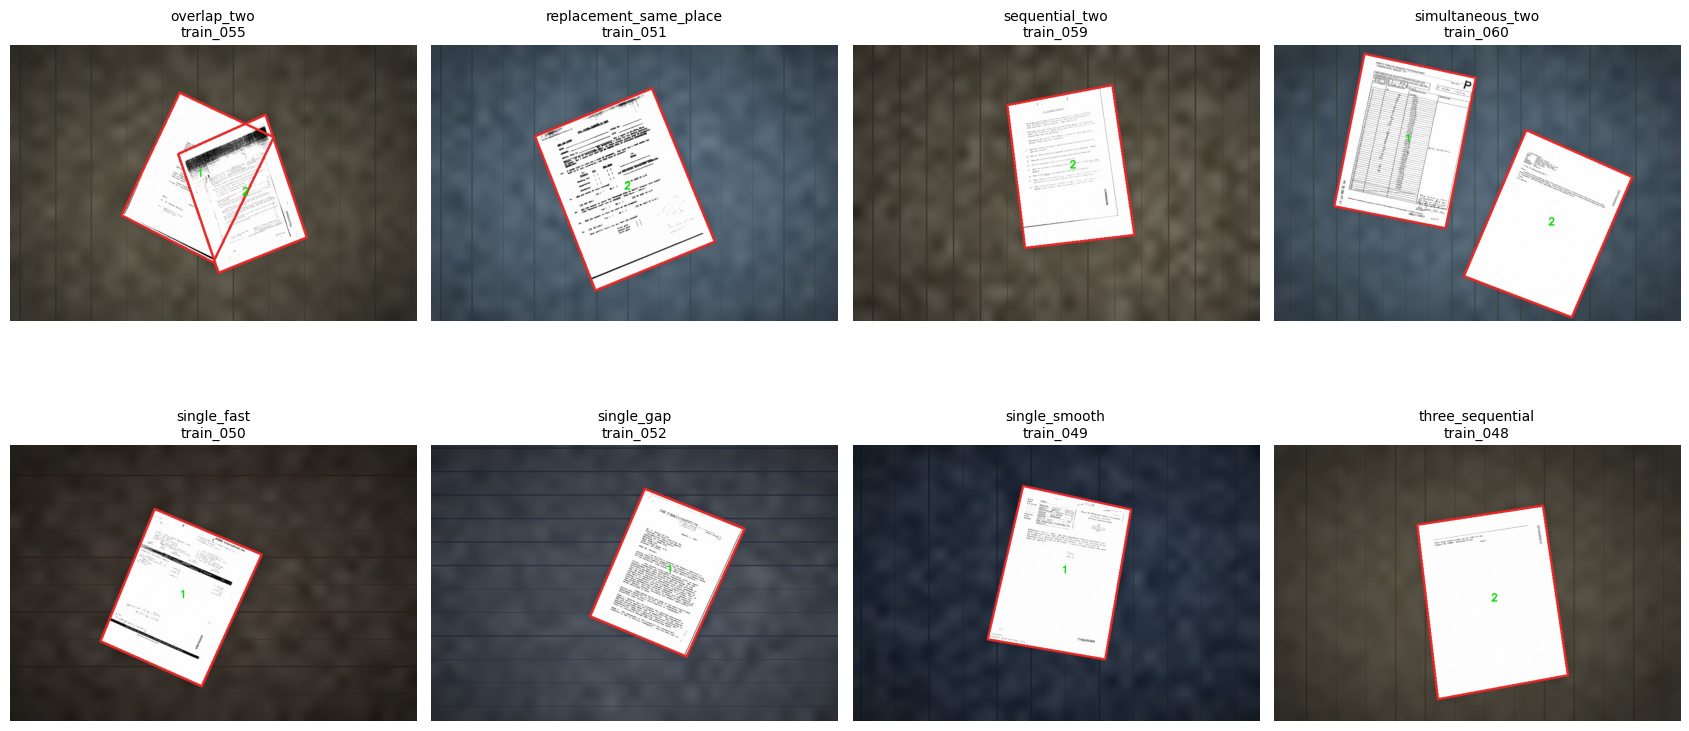

In [4]:
# --- Смотрим по одному примеру каждого сценария (инфраструктура) ---
examples = (
    clip_splits.sort_values(['scenario', 'subset', 'clip'])
    .drop_duplicates('scenario')
)
fig, axes = plt.subplots(2, 4, figsize=(17, 9))
for axis, (_, item) in zip(axes.ravel(), examples.iterrows()):
    clip = item['clip']
    candidates = labelled[
        (labelled['clip'] == clip)
        & (labelled['classification_ok'] == 1)
    ]
    if candidates.empty:
        candidates = labelled[labelled['clip'] == clip]
    row = candidates.iloc[len(candidates) // 2]
    image = read_frame('train', clip, row['frame'], rgb=False)
    same_frame = labelled[(labelled['clip'] == clip) & (labelled['frame'] == row['frame'])]
    for _, obj in same_frame.iterrows():
        quad = np.asarray(json.loads(obj['quad']), np.int32)
        cv2.polylines(image, [quad], True, (40, 40, 230), 3)
        centre = tuple(np.mean(quad, axis=0).astype(int))
        cv2.putText(image, str(int(obj['track_num'])), centre,
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, (20, 220, 20), 2)
    axis.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    axis.axis('off')
    axis.set_title(f"{item['scenario']}\n{clip}", fontsize=10)
plt.tight_layout()
plt.show()


## ✍️ Рефлексия ДО старта

1. Почему mAP детектора не гарантирует правильное число физических документов в записи?  
   ✍️ Ваш ответ: mAP усредняется по отдельным кадрам. Эта метрика не учитывает агрегацию во времени и не считает уникальные объекты в пределах записи.  
   Даже при высоком mAP возможны дублирующиеся рамки, ложные срабатывания, пропуски и срабатывания на перекрытых документах. Поэтому рабочий порог и устранение дубликатов калибруются отдельно.

2. Почему нельзя считать соседние кадры одного трека независимыми примерами классификации?  
   ✍️ Ваш ответ: соседние кадры трека почти дублируют друг друга. У них один и тот же объект, коррелированные пиксели, одинаковое размытие, освещение и артефакты сжатия.  
   Такие кадры не являются независимыми и одинаково распределёнными. Если разбивать выборку по кадрам, данные утекают из обучения в проверку, метрики завышаются, а модель переобучается на внешний вид конкретных документов и фонов.

3. В каком порядке должны подбираться параметры и где должен оставаться независимый holdout?  
   ✍️ Ваш ответ: в самом начале выборка разбивается на группы по записи, треку или источнику: обучающая, валидационная и отложенная тестовая. Тестовая выборка не используется до финальной проверки.  
   Порядок такой:  
   1. Детектор обучается на обучающей выборке, лучшая версия выбирается по валидационной, после чего детектор фиксируется.  
   2. Трекер настраивается на валидационной выборке по метрикам трекинга и по итоговому подсчёту документов.  
   3. Классификатор обучается на фрагментах изображений, собранных на уровне треков.  
   4. Пороги и устранение дубликатов калибруются на валидационной выборке.  
   5. На отложенной тестовой выборке делается один финальный прогон.

## Шаг 1. Детектор документа: ключевые кадры и YOLO


In [5]:
# --- TODO 1.1: переведите автоматическую разметку в формат YOLO ---
# --- TODO 1.1: четыре угла -> YOLO-рамка ---
def quad_to_yolo_line(quad_json, width, height, class_index=0):
    points = np.asarray(json.loads(quad_json), np.float32)

    # TODO 1.1a. Найдите x0, y0, x1, y1 по четырем углам
    # и обрежьте координаты по границам кадра.
    xs = points[:, 0]
    ys = points[:, 1]
    x0 = float(np.clip(xs.min(), 0.0, width))
    y0 = float(np.clip(ys.min(), 0.0, height))
    x1 = float(np.clip(xs.max(), 0.0, width))
    y1 = float(np.clip(ys.max(), 0.0, height))
    bounds = (x0, y0, x1, y1)
    if bounds is Ellipsis:
        raise NotImplementedError('Заполните TODO 1.1a: рамка и clipping')
    x0, y0, x1, y1 = bounds
    if x1 - x0 < 2 or y1 - y0 < 2:
        return None

    # TODO 1.1b. Переведите центр, ширину и высоту в доли кадра.
    cx = (x0 + x1) / 2.0 / width
    cy = (y0 + y1) / 2.0 / height
    bw = (x1 - x0) / width
    bh = (y1 - y0) / height
    normalized = (cx, cy, bw, bh)
    if normalized is Ellipsis:
        raise NotImplementedError('Заполните TODO 1.1b: нормированные cx, cy, bw, bh')
    cx, cy, bw, bh = normalized
    return f'{class_index} {cx:.6f} {cy:.6f} {bw:.6f} {bh:.6f}'
YOLO_DIR = Path('/content/yolo_dataset_v2')
shutil.rmtree(YOLO_DIR, ignore_errors=True)
for split in ('train', 'val'):
    (YOLO_DIR / 'images' / split).mkdir(parents=True)
    (YOLO_DIR / 'labels' / split).mkdir(parents=True)

def build_yolo_split(split_name, clips):
    selected_frames = frame_table[
        frame_table['clip'].isin(clips)
        & (frame_table['detector_keyframe'] == 1)
    ]
    written = 0
    objects_written = 0
    for _, frame_row in selected_frames.iterrows():
        clip, frame_name = frame_row['clip'], frame_row['frame']
        stem = f'{clip}_{Path(frame_name).stem}'
        src = VIDEO / 'train' / clip / frame_name
        dst = YOLO_DIR / 'images' / split_name / f'{stem}.jpg'
        shutil.copy2(src, dst)

        object_rows = labelled[
            (labelled['clip'] == clip)
            & (labelled['frame'] == frame_name)
        ]
        lines = []
        for _, obj in object_rows.iterrows():
            line = quad_to_yolo_line(obj['quad'], frame_row['width'], frame_row['height'])
            if line is not None:
                lines.append(line)
        (YOLO_DIR / 'labels' / split_name / f'{stem}.txt').write_text(
            '\n'.join(lines), encoding='utf-8'
        )
        written += 1
        objects_written += len(lines)
    return written, objects_written

n_train_images, n_train_objects = build_yolo_split('train', DETECTOR_TRAIN_CLIPS)
n_val_images, n_val_objects = build_yolo_split('val', DETECTOR_VAL_CLIPS)

data_yaml = YOLO_DIR / 'data.yaml'
data_yaml.write_text(
    f"path: {YOLO_DIR}\ntrain: images/train\nval: images/val\n"
    "names:\n  0: document\n",
    encoding='utf-8',
)
print('YOLO train:', n_train_images, 'кадров,', n_train_objects, 'объектов')
print('YOLO val:', n_val_images, 'кадров,', n_val_objects, 'объектов')

YOLO train: 840 кадров, 760 объектов
YOLO val: 168 кадров, 152 объектов


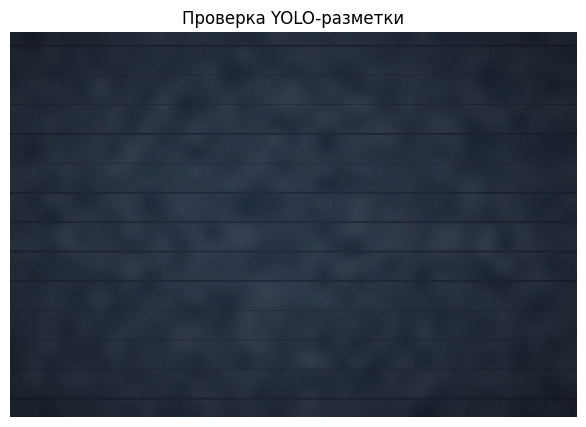

✅ разметка построена только на detector_keyframe и разделена по клипам


In [6]:
# --- ✅ Самопроверка разметки YOLO ---
train_images = sorted((YOLO_DIR / 'images' / 'train').glob('*.jpg'))
val_images = sorted((YOLO_DIR / 'images' / 'val').glob('*.jpg'))
assert train_images and val_images, 'YOLO train/val пусты'
assert not ({p.name for p in train_images} & {p.name for p in val_images}), 'train и val пересекаются'

sample_image_path = train_images[len(train_images) // 2]
sample_label_path = YOLO_DIR / 'labels' / 'train' / f'{sample_image_path.stem}.txt'
sample = cv2.imread(str(sample_image_path))
h, w = sample.shape[:2]
for line in sample_label_path.read_text(encoding='utf-8').splitlines():
    _, cx, cy, bw, bh = map(float, line.split())
    x0, y0 = int((cx - bw / 2) * w), int((cy - bh / 2) * h)
    x1, y1 = int((cx + bw / 2) * w), int((cy + bh / 2) * h)
    cv2.rectangle(sample, (x0, y0), (x1, y1), (50, 220, 50), 3)
plt.figure(figsize=(8, 5))
plt.imshow(cv2.cvtColor(sample, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.title('Проверка YOLO-разметки')
plt.show()
print('✅ разметка построена только на detector_keyframe и разделена по клипам')


In [7]:
# --- Обучение или повторная загрузка YOLO (инфраструктура) ---
# Первый запуск обучит модель. Повторный запуск после ошибки загрузит сохраненный best.pt.
FORCE_RETRAIN_DETECTOR = False
EPOCHS_DET = 40
DATASET_TAG = (
    f"schema{manifest.get('schema_version', 0)}_{DATASET_FINGERPRINT}_"
    f"tr{len(DETECTOR_TRAIN_CLIPS)}_va{len(DETECTOR_VAL_CLIPS)}"
)
DETECTOR_RUN_NAME = f'dz4_detector_{DATASET_TAG}'
DETECTOR_RUN_DIR = CONTENT / 'runs' / DETECTOR_RUN_NAME
DETECTOR_WEIGHTS = DETECTOR_RUN_DIR / 'weights' / 'best.pt'
RESULTS_CSV = DETECTOR_RUN_DIR / 'results.csv'

if FORCE_RETRAIN_DETECTOR:
    shutil.rmtree(DETECTOR_RUN_DIR, ignore_errors=True)

if not DETECTOR_WEIGHTS.exists():
    print('обучаем YOLO:', DETECTOR_RUN_NAME)
    detector_train = YOLO('yolov8n.pt')
    detector_train.train(
        data=str(data_yaml),
        epochs=EPOCHS_DET,
        imgsz=640,
        batch=16,
        seed=SEED,
        patience=8,
        workers=2,
        verbose=False,
        plots=False,
        project=str(CONTENT / 'runs'),
        name=DETECTOR_RUN_NAME,
        exist_ok=True,
    )
else:
    print('✅ найден сохраненный best.pt — повторное обучение пропущено')

if not DETECTOR_WEIGHTS.exists():
    raise FileNotFoundError(f'Не найден {DETECTOR_WEIGHTS}')
detector = YOLO(str(DETECTOR_WEIGHTS))

if RESULTS_CSV.exists():
    detector_history = pd.read_csv(RESULTS_CSV)
    detector_history.columns = [column.strip() for column in detector_history.columns]
    DETECTOR_EPOCHS = len(detector_history)
    DET_MAP50 = float(detector_history['metrics/mAP50(B)'].max())
    DET_MAP = float(detector_history['metrics/mAP50-95(B)'].max())
else:
    validation = detector.val(data=str(data_yaml), imgsz=640, split='val', verbose=False)
    detector_history = pd.DataFrame()
    DETECTOR_EPOCHS = None
    DET_MAP50 = float(validation.box.map50)
    DET_MAP = float(validation.box.map)

print(f'mAP50={DET_MAP50:.4f} | mAP50-95={DET_MAP:.4f}')

def detect_candidates(image_bgr, min_confidence=0.05):
    result = detector.predict(
        source=image_bgr,
        conf=float(min_confidence),
        iou=0.70,
        imgsz=640,
        verbose=False,
    )[0]
    if result.boxes is None or len(result.boxes) == 0:
        return []
    boxes = result.boxes.xyxy.detach().cpu().numpy().astype(np.float32)
    scores = result.boxes.conf.detach().cpu().numpy().astype(float)
    return [
        {'box': box, 'score': float(score)}
        for box, score in zip(boxes, scores)
    ]


обучаем YOLO: dz4_detector_schema2_e06346a291e0_tr40_va8
New https://pypi.org/project/ultralytics/8.4.216 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.117 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_dataset_v2/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.

### ✍️ Отчетная ячейка Шага 1

1. Сколько keyframes попало в train и validation и почему не использовались все 40 кадров каждого клипа:  
   В train 840 keyframes с 760 документами из 40 клипов, в val 168 keyframes со 152 документами из 8 клипов, то есть по 21 кадру на клип.  
   Все 40 кадров не брали, потому что соседние кадры почти одинаковы и не добавляют информации, только увеличивают время обучения и завышают уверенность модели. Деление сделано по клипам, поэтому кадры одного клипа не попадают в обе части, а пустые кадры без документа оставлены как негативы.

2. На какой эпохе остановилось обучение и чему равны mAP50 и mAP50–95:  
   Обучение остановилось на 16-й эпохе, лучшая эпоха — 8-я, сработал patience=8.  
   На валидации mAP50 = 0.995, mAP50–95 = 0.955.

3. Почему высокий покадровый mAP еще не гарантирует хороший трекинг:  
   mAP оценивает каждый кадр отдельно, а трекингу нужен один и тот же номер документа через все кадры записи.  
   Один пропущенный кадр, смаз при быстром движении или перекрытие рукой разрывают трек, и документ считается дважды — это видно по числам: при mAP50 = 0.995 на holdout трекера в 2 из 8 клипов посчитан лишний документ.

## Шаг 2. Устойчивый трекинг через восемь сценариев


In [9]:
# --- TODO 2.1–2.2: признаки сопоставления и трекер ---
def box_iou(first, second):
    a = np.asarray(first, np.float32)
    b = np.asarray(second, np.float32)
    # TODO 2.1. Найдите площадь пересечения и объединения двух рамок.
    ix0 = max(a[0], b[0])
    iy0 = max(a[1], b[1])
    ix1 = min(a[2], b[2])
    iy1 = min(a[3], b[3])
    inter_w = max(0.0, ix1 - ix0)
    inter_h = max(0.0, iy1 - iy0)
    inter = inter_w * inter_h
    area_a = max(0.0, a[2] - a[0]) * max(0.0, a[3] - a[1])
    area_b = max(0.0, b[2] - b[0]) * max(0.0, b[3] - b[1])
    union = area_a + area_b - inter
    value = inter / union if union > 1e-6 else 0.0
    if value is Ellipsis:
        raise NotImplementedError('Заполните TODO 2.1: IoU = intersection / union')
    return float(value)


def box_centre(box):
    box = np.asarray(box, np.float32)
    return np.array([(box[0] + box[2]) / 2, (box[1] + box[3]) / 2], np.float32)


def box_area(box):
    box = np.asarray(box, np.float32)
    return float(max(1.0, (box[2] - box[0]) * (box[3] - box[1])))


def document_features(image_bgr, box, size=28):
    """Компактный образ страницы, качество кадра и признак отступа от границ."""
    height, width = image_bgr.shape[:2]
    x0, y0, x1, y1 = np.asarray(box, int)
    x0, y0 = max(0, x0), max(0, y0)
    x1, y1 = min(width, x1), min(height, y1)
    crop = image_bgr[y0:y1, x0:x1]
    if crop.size == 0:
        return np.zeros(size * size * 2, np.float32), 0.0, False

    raw_gray = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)
    sharpness = float(cv2.Laplacian(raw_gray, cv2.CV_64F).var())
    quality = float(np.log1p(max(sharpness, 0.0)))

    gray = cv2.resize(raw_gray, (size, size), interpolation=cv2.INTER_AREA)
    gray = cv2.equalizeHist(gray).astype(np.float32) / 255.0
    gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)
    gradient = np.sqrt(gx * gx + gy * gy)
    descriptor = np.concatenate([gray.ravel(), gradient.ravel()]).astype(np.float32)
    descriptor -= descriptor.mean()
    norm = float(np.linalg.norm(descriptor))
    descriptor = descriptor / norm if norm > 1e-6 else np.zeros_like(descriptor)

    margin = 0.015 * min(height, width)
    border_clear = bool(
        x0 > margin and y0 > margin
        and x1 < width - margin and y1 < height - margin
    )
    return descriptor, quality, border_clear


def appearance_similarity(first, second):
    if first is None or second is None:
        return 0.5
    first = np.asarray(first, np.float32)
    second = np.asarray(second, np.float32)
    if not first.any() or not second.any():
        return 0.5
    cosine = float(np.clip(np.dot(first, second), -1.0, 1.0))
    return 0.5 * (cosine + 1.0)


def enrich_detections(image_bgr, detections):
    enriched = []
    for item in detections:
        descriptor, quality, border_clear = document_features(image_bgr, item['box'])
        enriched.append({
            **item,
            'box': np.asarray(item['box'], np.float32),
            'descriptor': descriptor,
            'quality': float(quality),
            'border_clear': bool(border_clear),
        })
    return enriched


class RobustDocumentTracker:
    """Трекер: движение + центр + размер + внешний вид документа.

    Банк опорных дескрипторов блокируется после нескольких кадров. Поэтому
    краткая потеря одного листа восстанавливает прежний track_id, а новый лист,
    появившийся в том же месте, создает новый track_id.
    """

    def __init__(
        self,
        min_affinity=0.36,
        max_lost=4,
        min_length=3,
        centre_gate=0.24,
        appearance_gate=0.75,
        frame_shape=(576, 848),
    ):
        self.min_affinity = float(min_affinity)
        self.max_lost = int(max_lost)
        self.min_length = int(min_length)
        self.centre_gate = float(centre_gate)
        self.appearance_gate = float(appearance_gate)
        self.replacement_gate = min(0.95, self.appearance_gate + 0.05)
        self.frame_shape = tuple(frame_shape)
        self.diagonal = float(math.hypot(frame_shape[0], frame_shape[1]))
        self.active = {}
        self.completed = {}
        self.next_id = 1

    @staticmethod
    def _reference_similarity(track, descriptor):
        bank = track.get('reference_bank', [])
        if not bank:
            return appearance_similarity(track.get('descriptor'), descriptor)
        return max(appearance_similarity(reference, descriptor) for _, reference in bank)

    @staticmethod
    def _add_reference(track, detection, limit=3):
        bank = list(track.get('reference_bank', []))
        bank.append((float(detection['quality']), detection['descriptor'].copy()))
        bank.sort(key=lambda item: item[0], reverse=True)
        track['reference_bank'] = bank[:limit]
        track['reference_quality'] = max((quality for quality, _ in bank), default=0.0)

    def _predicted_box(self, track):
        steps = track['lost'] + 1
        return track['box'] + track['velocity'] * steps

    def _affinity(self, track, detection):
        predicted = self._predicted_box(track)
        candidate = detection['box']
        iou = box_iou(predicted, candidate)
        distance = float(np.linalg.norm(box_centre(predicted) - box_centre(candidate)))
        normalized_distance = distance / max(self.diagonal, 1.0)
        centre_similarity = math.exp(-0.5 * (normalized_distance / self.centre_gate) ** 2)

        area_ratio = box_area(candidate) / box_area(predicted)
        if area_ratio < 0.25 or area_ratio > 4.0:
            return -np.inf
        size_similarity = math.exp(-abs(math.log(area_ratio)))

        reference_similarity = self._reference_similarity(track, detection['descriptor'])
        recent_similarity = appearance_similarity(track['descriptor'], detection['descriptor'])
        appearance = max(reference_similarity, recent_similarity)

        if iou < 1e-4 and normalized_distance > self.centre_gate * 1.25:
            return -np.inf

        reference_quality = max(float(track.get('reference_quality', 0.0)), 1e-6)
        candidate_is_readable = detection['quality'] >= max(2.0, 0.45 * reference_quality)
        reference_locked = track['length'] >= 6

        # После пропуска кадров отличающийся читаемый лист — это новый объект.
        if (
            reference_locked and track['lost'] > 0 and candidate_is_readable
            and reference_similarity < self.appearance_gate
        ):
            return -np.inf

        # Замена листа в том же месте может пройти без длинного пустого интервала.
        # Разделяем треки только на хорошем кадре внутри границ, чтобы не дробить
        # один лист на смазанных входных/выходных кадрах.
        replacement = (
            reference_locked
            and detection['border_clear']
            and candidate_is_readable
            and reference_similarity < self.replacement_gate
            and iou > 0.10
            and normalized_distance < self.centre_gate * 0.80
        )
        if replacement:
            return -np.inf

        # TODO 2.2. Соберите affinity из четырех признаков. Сумма весов — 1.
        score = (
            0.30 * iou
            + 0.30 * centre_similarity
            + 0.15 * size_similarity
            + 0.25 * appearance
        )
        if score is Ellipsis:
            raise NotImplementedError('Заполните TODO 2.2: affinity')
        return float(score)

    def update(self, detections, frame_order):
        detections = list(detections)
        track_ids = list(self.active)
        assignments = []
        used_tracks, used_detections = set(), set()

        if track_ids and detections:
            affinity = np.full((len(track_ids), len(detections)), -1e6, np.float32)
            for row_index, track_id in enumerate(track_ids):
                for col_index, detection in enumerate(detections):
                    value = self._affinity(self.active[track_id], detection)
                    if np.isfinite(value):
                        affinity[row_index, col_index] = value

            rows, cols = linear_sum_assignment(-affinity)
            for row_index, col_index in zip(rows, cols):
                value = float(affinity[row_index, col_index])
                if value < self.min_affinity:
                    continue
                track_id = track_ids[row_index]
                detection = detections[col_index]
                track = self.active[track_id]

                delta = detection['box'] - track['box']
                track['velocity'] = 0.65 * track['velocity'] + 0.35 * delta
                track['box'] = detection['box'].copy()
                track['lost'] = 0
                track['length'] += 1
                track['last_order'] = int(frame_order)

                combined = 0.85 * track['descriptor'] + 0.15 * detection['descriptor']
                norm = float(np.linalg.norm(combined))
                track['descriptor'] = combined / norm if norm > 1e-6 else combined

                reference_similarity = self._reference_similarity(track, detection['descriptor'])
                if track['length'] <= 6 or reference_similarity >= self.appearance_gate:
                    self._add_reference(track, detection)

                track['history'].append(detection['box'].copy())
                assignments.append((track_id, detection))
                used_tracks.add(track_id)
                used_detections.add(col_index)

        for track_id, track in list(self.active.items()):
            if track_id not in used_tracks:
                track['lost'] += 1

        for detection_index, detection in enumerate(detections):
            if detection_index in used_detections:
                continue
            track_id = self.next_id
            self.next_id += 1
            self.active[track_id] = {
                'box': detection['box'].copy(),
                'velocity': np.zeros(4, np.float32),
                'descriptor': detection['descriptor'].copy(),
                'reference_bank': [(float(detection['quality']), detection['descriptor'].copy())],
                'reference_quality': float(detection['quality']),
                'lost': 0,
                'length': 1,
                'first_order': int(frame_order),
                'last_order': int(frame_order),
                'history': [detection['box'].copy()],
            }
            assignments.append((track_id, detection))

        expired = [
            track_id for track_id, track in self.active.items()
            if track['lost'] > self.max_lost
        ]
        for track_id in expired:
            track = self.active.pop(track_id)
            if track['length'] >= self.min_length:
                self.completed[track_id] = track
        return sorted(assignments, key=lambda pair: pair[0])

    def finalize(self):
        for track_id, track in list(self.active.items()):
            if track['length'] >= self.min_length:
                self.completed[track_id] = track
        self.active.clear()
        return self.completed

    def count(self):
        return len(self.completed) + sum(
            track['length'] >= self.min_length for track in self.active.values()
        )

In [10]:
# --- Кешируем детекции на development: YOLO запускается ровно один раз на кадр ---
MIN_CACHE_CONFIDENCE = 0.05
DEVELOPMENT_DETECTION_CACHE = {}
for clip in DEVELOPMENT_CLIPS:
    rows = frame_table[frame_table['clip'] == clip].sort_values('order')
    per_frame = []
    for _, row in rows.iterrows():
        image_bgr = read_frame('train', clip, row['frame'], rgb=False)
        detections = detect_candidates(image_bgr, min_confidence=MIN_CACHE_CONFIDENCE)
        per_frame.append({
            'order': int(row['order']),
            'frame': row['frame'],
            'detections': enrich_detections(image_bgr, detections),
        })
    DEVELOPMENT_DETECTION_CACHE[clip] = per_frame
print('закешировано development-кадров:', sum(map(len, DEVELOPMENT_DETECTION_CACHE.values())))


закешировано development-кадров: 640


In [11]:
# --- TODO 2.3: подбор трекера только на calibration-клипах  ---
# Подберите несколько осмысленных значений каждого параметра.
DETECTION_THRESHOLDS = [0.25, 0.35, 0.45]
MIN_AFFINITIES = [0.30, 0.36, 0.42]
MAX_LOST_VALUES = [3, 4, 6]
MIN_LENGTH_VALUES = [2, 3, 4]
APPEARANCE_GATES = [0.70, 0.75, 0.80]
if any(value is Ellipsis for value in (
    DETECTION_THRESHOLDS, MIN_AFFINITIES, MAX_LOST_VALUES,
    MIN_LENGTH_VALUES, APPEARANCE_GATES,
)):
    raise NotImplementedError('Заполните TODO 2.3: сетка параметров')

truth_documents = dict(zip(clip_splits['clip'], clip_splits['documents']))
scenario_by_clip = dict(zip(clip_splits['clip'], clip_splits['scenario']))


def run_tracker_from_cache(clip, parameters):
    tracker = RobustDocumentTracker(
        min_affinity=parameters['min_affinity'],
        max_lost=parameters['max_lost'],
        min_length=parameters['min_length'],
        appearance_gate=parameters['appearance_gate'],
        frame_shape=(int(manifest['frame_size'][1]), int(manifest['frame_size'][0])),
    )
    for frame in DEVELOPMENT_DETECTION_CACHE[clip]:
        selected = [
            item for item in frame['detections']
            if item['score'] >= parameters['detection_threshold']
        ]
        tracker.update(selected, frame['order'])
    tracker.finalize()
    return len(tracker.completed)


def evaluate_tracker(clips, parameters):
    rows = []
    for clip in clips:
        prediction = run_tracker_from_cache(clip, parameters)
        truth = int(truth_documents[clip])
        rows.append({
            'clip': clip,
            'scenario': scenario_by_clip[clip],
            'truth': truth,
            'prediction': prediction,
            'error': prediction - truth,
        })
    return pd.DataFrame(rows)


grid_rows = []
for detection_threshold, min_affinity, max_lost, min_length, appearance_gate in product(
    DETECTION_THRESHOLDS, MIN_AFFINITIES, MAX_LOST_VALUES,
    MIN_LENGTH_VALUES, APPEARANCE_GATES,
):
    parameters = {
        'detection_threshold': float(detection_threshold),
        'min_affinity': float(min_affinity),
        'max_lost': int(max_lost),
        'min_length': int(min_length),
        'appearance_gate': float(appearance_gate),
    }
    predictions = evaluate_tracker(TRACKER_CALIBRATION_CLIPS, parameters)
    errors = predictions['error']
    grid_rows.append({
        **parameters,
        'mae': float(errors.abs().mean()),
        'exact_share': float((errors == 0).mean()),
        'bias': float(errors.mean()),
        'abs_bias': float(abs(errors.mean())),
        'overcount': int((errors > 0).sum()),
        'undercount': int((errors < 0).sum()),
    })

tracker_grid = pd.DataFrame(grid_rows).sort_values(
    ['mae', 'exact_share', 'abs_bias', 'overcount', 'undercount', 'max_lost'],
    ascending=[True, False, True, True, True, True],
).reset_index(drop=True)
best = tracker_grid.iloc[0]
TRACKER_PARAMS = {
    'detection_threshold': float(best['detection_threshold']),
    'min_affinity': float(best['min_affinity']),
    'max_lost': int(best['max_lost']),
    'min_length': int(best['min_length']),
    'appearance_gate': float(best['appearance_gate']),
}
tracker_calibration_results = evaluate_tracker(TRACKER_CALIBRATION_CLIPS, TRACKER_PARAMS)
tracker_holdout_results = evaluate_tracker(TRACKER_HOLDOUT_CLIPS, TRACKER_PARAMS)
TRACKER_CALIBRATION_MAE = float(tracker_calibration_results['error'].abs().mean())
TRACKER_HOLDOUT_MAE = float(tracker_holdout_results['error'].abs().mean())
TRACKER_HOLDOUT_EXACT = float((tracker_holdout_results['error'] == 0).mean())

print('лучшие варианты на calibration:')
display(tracker_grid.head(10))
print('выбранные параметры:', TRACKER_PARAMS)
print(f'calibration MAE: {TRACKER_CALIBRATION_MAE:.3f}')
print(f'holdout MAE: {TRACKER_HOLDOUT_MAE:.3f} | exact: {TRACKER_HOLDOUT_EXACT:.0%}')
display(tracker_holdout_results.sort_values('scenario'))

лучшие варианты на calibration:


,detection_threshold,min_affinity,max_lost,min_length,appearance_gate,mae,exact_share,bias,abs_bias,overcount,undercount
0,0.35,0.30,3,4,0.7,0.25,0.75,0.25,0.25,2,0
1,0.35,0.36,3,4,0.7,0.25,0.75,0.25,0.25,2,0
2,0.35,0.42,3,4,0.7,0.25,0.75,0.25,0.25,2,0
3,0.45,0.30,3,4,0.7,0.25,0.75,0.25,0.25,2,0
4,0.45,0.36,3,4,0.7,0.25,0.75,0.25,0.25,2,0
5,0.45,0.42,3,4,0.7,0.25,0.75,0.25,0.25,2,0
6,0.35,0.30,4,4,0.7,0.25,0.75,0.25,0.25,2,0
7,0.35,0.36,4,4,0.7,0.25,0.75,0.25,0.25,2,0
8,0.35,0.42,4,4,0.7,0.25,0.75,0.25,0.25,2,0
9,0.45,0.30,4,4,0.7,0.25,0.75,0.25,0.25,2,0


выбранные параметры: {'detection_threshold': 0.35, 'min_affinity': 0.3, 'max_lost': 3, 'min_length': 4, 'appearance_gate': 0.7}
calibration MAE: 0.250
holdout MAE: 0.250 | exact: 75%


,clip,scenario,truth,prediction,error
2,train_056,overlap_two,2,3,1
1,train_054,replacement_same_place,2,2,0
5,train_059,sequential_two,2,2,0
7,train_063,simultaneous_two,2,2,0
6,train_061,single_fast,1,2,1
3,train_057,single_gap,1,1,0
4,train_058,single_smooth,1,1,0
0,train_053,three_sequential,3,3,0


In [12]:
# --- ✅ Самопроверка Шага 2 ---
assert len(TRACKER_CALIBRATION_CLIPS) == len(SCENARIOS)
assert len(TRACKER_HOLDOUT_CLIPS) == len(SCENARIOS)
assert set(tracker_holdout_results['scenario']) == set(SCENARIOS)
assert TRACKER_PARAMS['max_lost'] >= 2, 'max_lost=1 не проверяет устойчивость к single_gap'
assert 0.5 <= TRACKER_PARAMS['appearance_gate'] <= 0.95

# Три маленьких теста логики без YOLO.
_descriptor_size = 28 * 28 * 2
_desc_a = np.zeros(_descriptor_size, np.float32); _desc_a[0] = 1.0
_desc_b = np.zeros(_descriptor_size, np.float32); _desc_b[1] = 1.0

def _synthetic_detection(box, descriptor):
    return {
        'box': np.asarray(box, np.float32), 'score': 0.9,
        'descriptor': descriptor.copy(), 'quality': 6.0, 'border_clear': True,
    }

def _synthetic_count(frames):
    tracker = RobustDocumentTracker(
        min_affinity=TRACKER_PARAMS['min_affinity'],
        max_lost=max(4, TRACKER_PARAMS['max_lost']),
        min_length=TRACKER_PARAMS['min_length'],
        appearance_gate=TRACKER_PARAMS['appearance_gate'],
        frame_shape=(576, 848),
    )
    for order, detections in enumerate(frames):
        tracker.update(detections, order)
    return len(tracker.finalize())

_smooth = [[_synthetic_detection([100+i*3, 100, 300+i*3, 400], _desc_a)] for i in range(20)]
_gap = [
    [] if 9 <= i <= 12 else [_synthetic_detection([100+i*3, 100, 300+i*3, 400], _desc_a)]
    for i in range(25)
]
_replacement = [
    [_synthetic_detection([100, 100, 300, 400], _desc_a if i < 10 else _desc_b)]
    for i in range(20)
]
assert _synthetic_count(_smooth) == 1, 'плавное движение должно давать один трек'
assert _synthetic_count(_gap) == 1, 'single_gap не должен дробить один документ'
assert _synthetic_count(_replacement) == 2, 'замена страницы в том же месте должна дать два трека'

print('✅ трекер подобран на 8 сценариях, проверен на других 8 клипах и прошел unit-тесты')
if TRACKER_HOLDOUT_EXACT < 0.75:
    print('⚠️ exact < 75%: проанализируйте сценарии с ошибками, а не маскируйте их общей MAE')


✅ трекер подобран на 8 сценариях, проверен на других 8 клипах и прошел unit-тесты


In [13]:
# --- Резервная копия весов YOLO на Drive ---
shutil.copytree(DETECTOR_RUN_DIR, f"/content/drive/MyDrive/mipt_cv/dz4_runs/{DETECTOR_RUN_NAME}", dirs_exist_ok=True)
print("сохранено:", DETECTOR_RUN_NAME)

сохранено: dz4_detector_schema2_e06346a291e0_tr40_va8


### ✍️ Отчетная ячейка Шага 2

1. Какие параметры победили и почему max_lost=1 опасен для single_gap:  
   Победили порог детектора 0.35, min_affinity 0.30, max_lost 3, min_length 4, appearance_gate 0.70.  
   Оговорки: сетка почти плоская, топ-10 дают MAE 0.25 и 75% точных, порог детектора и min_affinity не влияют, победителя выбрал порядок сортировки, а min_length 4 и appearance_gate 0.70 лежат на краях сетки.  
   max_lost=1 опасен для single_gap: документ пропадает на 4 кадра, трек удаляется после первого пропуска, вернувшийся лист получает новый номер, и вместо 1 документа считается 2.

2. На каких сценариях holdout появились ошибки, разрыв одного трека или склейка двух документов:  
   На holdout MAE 0.25 и точно 6 из 8 клипов, ошибки в overlap_two (3 вместо 2) и single_fast (2 вместо 1).  
   Обе ошибки со знаком плюс, то есть это разрывы одного документа на два трека, склеек двух документов в один нет.  
   Причина в быстром движении (предсказанная рамка не попадает на лист, сходство ниже порога) и в перекрытии (внешний вид меняется, срабатывает правило нового листа).

3. Что дал внешний вид документа в сценарии replacement_same_place:  
   Сценарий посчитан верно, 2 равно 2.  
   Новый лист в том же месте даёт те же IoU, центр и размер, что и старый, поэтому по одной геометрии трекер склеил бы их в один трек и недосчитал документ.  
   Разделяет их внешний вид: если сходство с банком опорных образов ниже appearance_gate, сопоставление запрещается и появляется новый трек.  
   Цена проверки видна в overlap_two, где при перекрытии тот же механизм ложно разрывает трек.

## Шаг 3. Выпрямление и oracle-проверка классификатора ДЗ 2


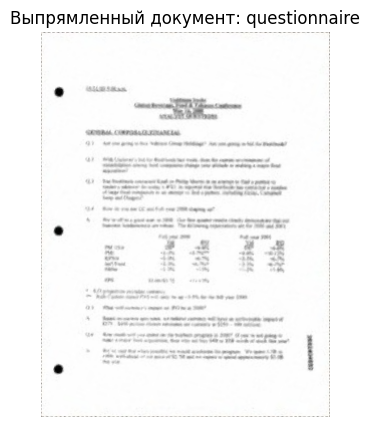

размер: 288 x 384


In [15]:
# --- TODO 3.1: выпрямление документа ---
# --- TODO 3.1: порядок углов и перспективное преобразование ---
def order_quad(points):
    """Возвращает углы в порядке: левый верхний, правый верхний, правый нижний, левый нижний."""
    pts = np.asarray(points, np.float32).reshape(4, 2)
    # Сортировка по углу вокруг центра даёт обход по часовой стрелке
    # (ось y в изображении направлена вниз) и не ломается при повороте на ~45°.
    center = pts.mean(axis=0)
    angles = np.arctan2(pts[:, 1] - center[1], pts[:, 0] - center[0])
    pts = pts[np.argsort(angles)]
    # Начинаем обход с левого верхнего угла: у него минимальна сумма x + y.
    start = int(np.argmin(pts.sum(axis=1)))
    ordered = np.roll(pts, -start, axis=0)
    return np.asarray(ordered, np.float32)

def warp_document(image_rgb, quad, long_side=384):
    points = order_quad(quad)
    tl, tr, br, bl = points
    # Размеры документа по длинным парам сторон
    width = max(np.linalg.norm(tr - tl), np.linalg.norm(br - bl))
    height = max(np.linalg.norm(bl - tl), np.linalg.norm(br - tr))
    # Масштаб: длинная сторона равна long_side, пропорции сохраняются
    scale = long_side / max(width, height, 1.0)
    out_w = max(1, int(round(width * scale)))
    out_h = max(1, int(round(height * scale)))
    destination = np.array([[0, 0],
                            [out_w - 1, 0],
                            [out_w - 1, out_h - 1],
                            [0, out_h - 1]], np.float32)
    homography = cv2.getPerspectiveTransform(points, destination)
    result = cv2.warpPerspective(image_rgb, homography, (out_w, out_h),
                                 flags=cv2.INTER_LINEAR,
                                 borderMode=cv2.BORDER_REPLICATE)
    return result

sample_row = labelled[labelled['classification_ok'] == 1].iloc[0]
sample_image = read_frame('train', sample_row['clip'], sample_row['frame'], rgb=True)
sample_flat = warp_document(sample_image, json.loads(sample_row['quad']))
plt.figure(figsize=(6, 5))
plt.imshow(sample_flat)
plt.axis('off')
plt.title(f"Выпрямленный документ: {sample_row['type']}")
plt.show()
print('размер:', sample_flat.shape[1], 'x', sample_flat.shape[0])

In [16]:
# --- Загрузка классификатора и точного контракта ДЗ 2 (инфраструктура) ---
metrics_dz2 = json.load(open(DZ2 / 'metrics.json', encoding='utf-8'))
config_path = DZ2 / 'model_config.json'
checkpoint_path = DZ2 / 'classifier.pt' if (DZ2 / 'classifier.pt').exists() else DZ2 / 'best_model.pt'
payload = torch.load(checkpoint_path, map_location='cpu')
state_dict = payload.get('state_dict', payload) if isinstance(payload, dict) else payload
embedded_config = payload.get('config', {}) if isinstance(payload, dict) else {}
state_dict = {str(key).removeprefix('module.'): value for key, value in state_dict.items()}

if config_path.exists():
    DZ2_MODEL_CONFIG = json.load(open(config_path, encoding='utf-8'))
    DZ2_CONFIG_SOURCE = 'model_config.json'
elif embedded_config:
    DZ2_MODEL_CONFIG = embedded_config
    DZ2_CONFIG_SOURCE = checkpoint_path.name + ':config'
else:
    raw_name = str(metrics_dz2.get('architecture', metrics_dz2.get('best_model', 'resnet18'))).lower()
    DZ2_MODEL_CONFIG = {
        'framework': 'torchvision' if raw_name.startswith(('resnet', 'mobilenet')) else 'timm',
        'architecture': 'resnet18' if raw_name.startswith('resnet18') else raw_name,
        'classes': list(metrics_dz2['classes']),
        'preprocessing': {
            'image_size': int(metrics_dz2.get('img_size', 224)),
            'input_color': 'grayscale_triplicate',
            'resize_policy': 'square_resize',
            'resize_interpolation': 'linear',
            'mean': [0.485, 0.456, 0.406],
            'std': [0.229, 0.224, 0.225],
        },
    }
    DZ2_CONFIG_SOURCE = 'legacy inference from metrics.json'

DZ2_CLASSES = list(DZ2_MODEL_CONFIG.get('classes', metrics_dz2['classes']))
DZ2_FRAMEWORK = str(DZ2_MODEL_CONFIG.get('framework', 'torchvision')).lower()
DZ2_ARCHITECTURE = str(DZ2_MODEL_CONFIG.get('architecture', 'resnet18')).lower()
DZ2_PREPROCESSING = dict(DZ2_MODEL_CONFIG.get('preprocessing', {}))
CLS_SIZE = int(DZ2_PREPROCESSING.get('image_size', 224))
MEAN = tuple(DZ2_PREPROCESSING.get('mean', (0.485, 0.456, 0.406)))
STD = tuple(DZ2_PREPROCESSING.get('std', (0.229, 0.224, 0.225)))
DZ2_INPUT_COLOR = str(DZ2_PREPROCESSING.get('input_color', 'grayscale_triplicate')).lower()
DZ2_RESIZE_POLICY = str(DZ2_PREPROCESSING.get('resize_policy', 'square_resize')).lower()
DZ2_RESIZE_INTERPOLATION = str(DZ2_PREPROCESSING.get('resize_interpolation', 'linear')).lower()

def build_dz2_model(framework, architecture, num_classes):
    if framework == 'torchvision':
        if architecture == 'resnet18':
            model = tv_models.resnet18(weights=None)
            model.fc = nn.Linear(model.fc.in_features, num_classes)
            return model, model.fc, model.layer4
        if architecture == 'resnet34':
            model = tv_models.resnet34(weights=None)
            model.fc = nn.Linear(model.fc.in_features, num_classes)
            return model, model.fc, model.layer4
        if architecture == 'mobilenet_v3_large':
            model = tv_models.mobilenet_v3_large(weights=None)
            model.classifier[-1] = nn.Linear(model.classifier[-1].in_features, num_classes)
            return model, model.classifier[-1], model.features[-3:]
        raise ValueError(f'Неподдерживаемая torchvision-архитектура: {architecture}')
    model = timm.create_model(architecture, pretrained=False, num_classes=num_classes)
    head = model.get_classifier()
    last_block = getattr(model, 'blocks', None)
    if last_block is not None:
        last_block = last_block[-1]
    return model, head, last_block

classifier, DZ2_HEAD, DZ2_LAST_BLOCK = build_dz2_model(
    DZ2_FRAMEWORK, DZ2_ARCHITECTURE, len(DZ2_CLASSES)
)
classifier.load_state_dict(state_dict, strict=True)
classifier = classifier.to(device).eval()

def dz2_interpolation():
    mapping = {
        'linear': cv2.INTER_LINEAR, 'bilinear': cv2.INTER_LINEAR,
        'area': cv2.INTER_AREA, 'nearest': cv2.INTER_NEAREST,
        'cubic': cv2.INTER_CUBIC,
    }
    if DZ2_RESIZE_INTERPOLATION not in mapping:
        raise ValueError('Неизвестная интерполяция ДЗ 2: ' + DZ2_RESIZE_INTERPOLATION)
    return mapping[DZ2_RESIZE_INTERPOLATION]

def prepare_dz2_image(image_rgb):
    array = np.asarray(image_rgb)
    if array.ndim == 2:
        array = np.repeat(array[..., None], 3, axis=2)
    array = np.clip(array, 0, 255).astype(np.uint8)
    if DZ2_INPUT_COLOR in {'grayscale', 'grayscale_triplicate', 'gray_triplicate'}:
        gray = cv2.cvtColor(array, cv2.COLOR_RGB2GRAY)
        array = np.repeat(gray[..., None], 3, axis=2)
    elif DZ2_INPUT_COLOR != 'rgb':
        raise ValueError('Неизвестный input_color: ' + DZ2_INPUT_COLOR)

    if DZ2_RESIZE_POLICY in {'fit_pad_white', 'fit_with_padding', 'letterbox_white'}:
        height, width = array.shape[:2]
        scale = min(CLS_SIZE / width, CLS_SIZE / height)
        new_width = max(1, int(round(width * scale)))
        new_height = max(1, int(round(height * scale)))
        resized = cv2.resize(array, (new_width, new_height), interpolation=dz2_interpolation())
        prepared = np.full((CLS_SIZE, CLS_SIZE, 3), 255, np.uint8)
        x0 = (CLS_SIZE - new_width) // 2
        y0 = (CLS_SIZE - new_height) // 2
        prepared[y0:y0 + new_height, x0:x0 + new_width] = resized
    elif DZ2_RESIZE_POLICY in {'square_resize', 'resize_square', 'stretch'}:
        prepared = cv2.resize(array, (CLS_SIZE, CLS_SIZE), interpolation=dz2_interpolation())
    else:
        raise ValueError('Неизвестный resize_policy: ' + DZ2_RESIZE_POLICY)
    return prepared

def dz2_tensor(image_rgb):
    prepared = prepare_dz2_image(image_rgb).astype(np.float32) / 255.0
    prepared = (prepared - np.asarray(MEAN, np.float32)) / np.asarray(STD, np.float32)
    return torch.from_numpy(prepared.transpose(2, 0, 1)).float()

@torch.no_grad()
def predict_probabilities(model, image_rgb):
    model.eval()
    tensor = dz2_tensor(image_rgb).unsqueeze(0).to(device)
    return F.softmax(model(tensor), dim=1)[0].cpu().numpy()

print('ДЗ 2:', DZ2_FRAMEWORK, DZ2_ARCHITECTURE, '| checkpoint:', checkpoint_path.name)
print('контракт:', DZ2_PREPROCESSING)


ДЗ 2: torchvision resnet18 | checkpoint: classifier.pt
контракт: {'image_size': 224, 'input_color': 'grayscale_triplicate', 'grayscale_to_rgb': True, 'resize_policy': 'square_resize', 'resize_interpolation': 'linear', 'mean': [0.485, 0.456, 0.406], 'std': [0.229, 0.224, 0.225]}


In [17]:
# --- Oracle-оценка ДЗ 2: истинные quad и track, без ошибок YOLO/трекера ---
def thin_track_rows(rows, per_track=6, seed=SEED):
    parts = []
    for _, group in rows.groupby(['clip', 'track_num'], sort=True):
        parts.append(group.sample(min(per_track, len(group)), random_state=seed))
    return pd.concat(parts, ignore_index=True) if parts else rows.iloc[0:0].copy()

classification_rows = labelled[labelled['classification_ok'] == 1].copy()
cls_fit_rows = thin_track_rows(
    classification_rows[classification_rows['clip'].isin(FIT_CLIPS)], per_track=6
)
cls_tuning_rows = thin_track_rows(
    classification_rows[classification_rows['clip'].isin(TRACKER_CALIBRATION_CLIPS)], per_track=6
)
cls_holdout_rows = thin_track_rows(
    classification_rows[classification_rows['clip'].isin(TRACKER_HOLDOUT_CLIPS)], per_track=6
)

def evaluate_classifier_tracks(model, rows):
    """Метрики по физическим документам после усреднения вероятностей кадров трека.

    Macro-F1 остается основной метрикой. Log loss используется как непрерывный
    вторичный критерий, когда на маленьком tuning-split несколько моделей дают
    одинаковый F1.
    """
    probabilities_by_track = collections.defaultdict(list)
    truth_by_track = {}

    for _, row in rows.iterrows():
        image = read_frame('train', row['clip'], row['frame'], rgb=True)
        document = warp_document(image, json.loads(row['quad']))
        probabilities = predict_probabilities(model, document)
        key = (row['clip'], int(row['track_num']))
        probabilities_by_track[key].append(probabilities)
        truth_by_track[key] = row['type']

    y_true, y_pred = [], []
    track_probabilities = []
    true_indices = []
    confidences = []
    margins = []
    true_probabilities = []

    for key, probability_list in probabilities_by_track.items():
        mean_probability = np.mean(np.stack(probability_list), axis=0).astype(np.float64)
        mean_probability = np.clip(mean_probability, 1e-8, 1.0)
        mean_probability = mean_probability / mean_probability.sum()

        truth = truth_by_track[key]
        truth_index = DZ2_CLASSES.index(truth)
        order = np.argsort(mean_probability)[::-1]
        predicted_index = int(order[0])

        y_true.append(truth)
        y_pred.append(DZ2_CLASSES[predicted_index])
        track_probabilities.append(mean_probability)
        true_indices.append(truth_index)
        confidences.append(float(mean_probability[predicted_index]))
        true_probabilities.append(float(mean_probability[truth_index]))
        margins.append(float(mean_probability[order[0]] - mean_probability[order[1]]))

    classes_present = sorted(set(y_true))
    probability_matrix = (
        np.stack(track_probabilities)
        if track_probabilities
        else np.empty((0, len(DZ2_CLASSES)), dtype=np.float64)
    )

    return {
        'macro_f1': float(f1_score(y_true, y_pred, average='macro', zero_division=0)) if y_true else 0.0,
        'accuracy': float(accuracy_score(y_true, y_pred)) if y_true else 0.0,
        'log_loss': float(log_loss(
            true_indices,
            probability_matrix,
            labels=list(range(len(DZ2_CLASSES))),
        )) if y_true else float('inf'),
        'y_true': y_true,
        'y_pred': y_pred,
        'tracks': len(y_true),
        'classes_present': classes_present,
        'mean_confidence': float(np.mean(confidences)) if confidences else 0.0,
        'mean_true_probability': float(np.mean(true_probabilities)) if true_probabilities else 0.0,
        'mean_margin': float(np.mean(margins)) if margins else 0.0,
    }

classifier_original = copy.deepcopy(classifier).to(device).eval()
ORACLE_BASELINE_TUNING = evaluate_classifier_tracks(classifier_original, cls_tuning_rows)
ORACLE_BASELINE_HOLDOUT = evaluate_classifier_tracks(classifier_original, cls_holdout_rows)
print('исходный артефакт ДЗ 2:')
print(
    '  tuning track-F1:', round(ORACLE_BASELINE_TUNING['macro_f1'], 3),
    '| tuning log loss:', round(ORACLE_BASELINE_TUNING['log_loss'], 4),
)
print(
    '  holdout track-F1:', round(ORACLE_BASELINE_HOLDOUT['macro_f1'], 3),
    '| holdout accuracy:', round(ORACLE_BASELINE_HOLDOUT['accuracy'], 3),
)
print(
    '  holdout документов:', ORACLE_BASELINE_HOLDOUT['tracks'],
    '| классы:', ORACLE_BASELINE_HOLDOUT['classes_present'],
)


исходный артефакт ДЗ 2:
  tuning track-F1: 0.783 | tuning log loss: 0.3897
  holdout track-F1: 0.774 | holdout accuracy: 0.857
  holdout документов: 14 | классы: ['budget', 'email', 'form', 'invoice', 'letter', 'memo', 'questionnaire', 'resume']


In [18]:
# --- TODO 3.2: адаптация готового классификатора к видеодомену ---
ADAPT_DZ2_ON_VIDEO = True
# Нужно ли кроме головы разморозить последний содержательный блок энкодера?
# Подсказка: это ограниченная адаптация, а не обучение всей сети с нуля.
UNFREEZE_LAST_BLOCK = True
if UNFREEZE_LAST_BLOCK is Ellipsis:
    raise NotImplementedError('Заполните TODO 3.2: размораживать ли последний блок')

class VideoDocumentDataset(Dataset):
    def __init__(self, rows, augment=False):
        self.rows = rows.reset_index(drop=True)
        self.class_to_idx = {name: index for index, name in enumerate(DZ2_CLASSES)}
        self.augmentation = transforms.Compose([
            transforms.ToPILImage(),
            transforms.RandomRotation(5, fill=255),
            transforms.RandomPerspective(distortion_scale=0.08, p=0.30, fill=255),
            transforms.ColorJitter(brightness=0.20, contrast=0.20),
            transforms.RandomApply([transforms.GaussianBlur(3)], p=0.15),
        ]) if augment else None

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows.iloc[index]
        image = read_frame('train', row['clip'], row['frame'], rgb=True)
        document = warp_document(image, json.loads(row['quad']))
        if self.augmentation is not None:
            document = np.asarray(self.augmentation(document))
        return dz2_tensor(document), self.class_to_idx[row['type']]

track_labels = cls_fit_rows.drop_duplicates(['clip', 'track_num'])['type']
class_counts = track_labels.value_counts().reindex(DZ2_CLASSES, fill_value=1)
class_weights = len(class_counts) / (len(class_counts) * class_counts.astype(float))
CLASS_WEIGHTS = torch.tensor(class_weights.values, dtype=torch.float32, device=device)

CLASSIFIER_HISTORY = pd.DataFrame()
# Собираем отдельного кандидата: исходный артефакт остается неизменным.
candidate_model, candidate_head, candidate_last = build_dz2_model(
    DZ2_FRAMEWORK, DZ2_ARCHITECTURE, len(DZ2_CLASSES)
)
candidate_model.load_state_dict(classifier_original.state_dict())
classifier_candidate = candidate_model.to(device)
for parameter in classifier_candidate.parameters():
    parameter.requires_grad = False

candidate_modules = [candidate_head]
if UNFREEZE_LAST_BLOCK and candidate_last is not None:
    candidate_modules.append(candidate_last)
for module in candidate_modules:
    for parameter in module.parameters():
        parameter.requires_grad = True

ORACLE_CANDIDATE_TUNING = None
ORACLE_CANDIDATE_HOLDOUT = None
CLASSIFIER_SELECTION_REASON = 'адаптация отключена'

if ADAPT_DZ2_ON_VIDEO:
    train_loader = DataLoader(
        VideoDocumentDataset(cls_fit_rows, augment=True),
        batch_size=32,
        shuffle=True,
        num_workers=2,
        pin_memory=(device == 'cuda'),
    )
    criterion = nn.CrossEntropyLoss(weight=CLASS_WEIGHTS)
    parameter_groups = [
        {'params': [p for p in candidate_head.parameters() if p.requires_grad], 'lr': 2e-4}
    ]
    last_parameters = (
        [p for p in candidate_last.parameters() if p.requires_grad]
        if UNFREEZE_LAST_BLOCK and candidate_last is not None
        else []
    )
    if last_parameters:
        parameter_groups.append({'params': last_parameters, 'lr': 1e-5})
    optimizer = torch.optim.AdamW(parameter_groups, weight_decay=1e-4)

    def frozen_batchnorm_eval(model):
        for module in model.modules():
            if isinstance(module, nn.BatchNorm2d):
                parameters = list(module.parameters(recurse=False))
                if parameters and not any(p.requires_grad for p in parameters):
                    module.eval()

    # При одинаковом F1 сохраняем самую раннюю эпоху. Это консервативнее
    # на маленьком tuning-split и не позволяет бесконечно повышать уверенность.
    best_tuning_f1 = -1.0
    best_state = copy.deepcopy(classifier_candidate.state_dict())
    history_rows = []
    waited = 0

    for epoch in range(1, 13):
        classifier_candidate.train()
        frozen_batchnorm_eval(classifier_candidate)
        running, seen = 0.0, 0

        for images, labels_batch in train_loader:
            images, labels_batch = images.to(device), labels_batch.to(device)
            optimizer.zero_grad()
            logits = classifier_candidate(images)
            loss = criterion(logits, labels_batch)
            loss.backward()
            optimizer.step()
            running += float(loss.item()) * images.size(0)
            seen += images.size(0)

        tuning = evaluate_classifier_tracks(classifier_candidate, cls_tuning_rows)
        history_rows.append({
            'epoch': epoch,
            'train_loss': running / max(seen, 1),
            'tuning_track_f1': tuning['macro_f1'],
            'tuning_log_loss': tuning['log_loss'],
            'tuning_accuracy': tuning['accuracy'],
            'tuning_mean_true_probability': tuning['mean_true_probability'],
        })

        if tuning['macro_f1'] > best_tuning_f1 + 1e-4:
            best_tuning_f1 = tuning['macro_f1']
            best_state = copy.deepcopy(classifier_candidate.state_dict())
            waited = 0
        else:
            waited += 1

        print(
            f"эпоха {epoch:2d}: loss {running/max(seen,1):.4f}, "
            f"tuning track-F1 {tuning['macro_f1']:.3f}, "
            f"log loss {tuning['log_loss']:.4f}"
        )
        if waited >= 3:
            break

    classifier_candidate.load_state_dict(best_state)
    classifier_candidate = classifier_candidate.to(device).eval()
    CLASSIFIER_HISTORY = pd.DataFrame(history_rows)

    ORACLE_CANDIDATE_TUNING = evaluate_classifier_tracks(
        classifier_candidate, cls_tuning_rows
    )
    ORACLE_CANDIDATE_HOLDOUT = evaluate_classifier_tracks(
        classifier_candidate, cls_holdout_rows
    )

    # Выбор original/adapted использует только tuning.
    # Macro-F1 — основной критерий. Если он совпал, дискретная метрика
    # насытилась; тогда корректным tie-breaker служит меньший log loss.
    candidate_f1 = ORACLE_CANDIDATE_TUNING['macro_f1']
    baseline_f1 = ORACLE_BASELINE_TUNING['macro_f1']
    candidate_nll = ORACLE_CANDIDATE_TUNING['log_loss']
    baseline_nll = ORACLE_BASELINE_TUNING['log_loss']

    adaptation_wins = (
        candidate_f1 > baseline_f1 + 1e-4
        or (
            abs(candidate_f1 - baseline_f1) <= 1e-4
            and candidate_nll < baseline_nll - 1e-4
        )
    )

    if adaptation_wins:
        classifier = classifier_candidate
        if candidate_f1 > baseline_f1 + 1e-4:
            CLASSIFIER_SELECTION_REASON = 'выше macro-F1 на tuning'
        else:
            CLASSIFIER_SELECTION_REASON = (
                'macro-F1 на tuning совпал; адаптация выбрана по меньшему log loss'
            )
        CLASSIFIER_SOURCE = 'ДЗ 2 + доменная адаптация на fit'
    else:
        classifier = classifier_original.to(device).eval()
        CLASSIFIER_SELECTION_REASON = (
            'адаптация не улучшила macro-F1 и log loss на tuning'
        )
        CLASSIFIER_SOURCE = 'исходный артефакт ДЗ 2'
else:
    classifier = classifier_original.to(device).eval()
    CLASSIFIER_SOURCE = 'исходный артефакт ДЗ 2'
    CLASSIFIER_SELECTION_REASON = 'адаптация отключена'

ORACLE_SELECTED_TUNING = evaluate_classifier_tracks(classifier, cls_tuning_rows)
ORACLE_SELECTED_HOLDOUT = evaluate_classifier_tracks(classifier, cls_holdout_rows)

print('\nисходная модель на tuning:')
print(
    f"  F1 {ORACLE_BASELINE_TUNING['macro_f1']:.3f}, "
    f"log loss {ORACLE_BASELINE_TUNING['log_loss']:.4f}"
)
if ORACLE_CANDIDATE_TUNING is not None:
    print('адаптированный кандидат на tuning:')
    print(
        f"  F1 {ORACLE_CANDIDATE_TUNING['macro_f1']:.3f}, "
        f"log loss {ORACLE_CANDIDATE_TUNING['log_loss']:.4f}"
    )
print('используемая модель:', CLASSIFIER_SOURCE)
print('причина выбора:', CLASSIFIER_SELECTION_REASON)
print(
    'oracle holdout track-F1:', round(ORACLE_SELECTED_HOLDOUT['macro_f1'], 3),
    '| accuracy:', round(ORACLE_SELECTED_HOLDOUT['accuracy'], 3),
    '| log loss:', round(ORACLE_SELECTED_HOLDOUT['log_loss'], 4),
)


эпоха  1: loss 0.9590, tuning track-F1 0.933, log loss 0.2151
эпоха  2: loss 0.5589, tuning track-F1 0.933, log loss 0.1975
эпоха  3: loss 0.3935, tuning track-F1 0.933, log loss 0.2265
эпоха  4: loss 0.2523, tuning track-F1 0.933, log loss 0.1978

исходная модель на tuning:
  F1 0.783, log loss 0.3897
адаптированный кандидат на tuning:
  F1 0.933, log loss 0.2151
используемая модель: ДЗ 2 + доменная адаптация на fit
причина выбора: выше macro-F1 на tuning
oracle holdout track-F1: 0.774 | accuracy: 0.857 | log loss: 0.4738


In [19]:
# --- ✅ Самопроверка Шага 3 ---
assert sample_flat.shape[0] > 50 and sample_flat.shape[1] > 50
source_quad = np.asarray(json.loads(sample_row['quad']), np.float32)
source_width = max(np.linalg.norm(source_quad[1] - source_quad[0]), np.linalg.norm(source_quad[2] - source_quad[3]))
source_height = max(np.linalg.norm(source_quad[2] - source_quad[1]), np.linalg.norm(source_quad[3] - source_quad[0]))
source_portrait = source_width < source_height
result_portrait = sample_flat.shape[1] < sample_flat.shape[0]
assert source_portrait == result_portrait, 'Выпрямление поменяло книжную ориентацию на альбомную'
print('✅ классификатор оценен отдельно от YOLO/трекера на истинных физических документах')
if ORACLE_SELECTED_HOLDOUT['macro_f1'] < 0.50:
    print('⚠️ Даже oracle track-F1 ниже 0.50: проблема в переносе ДЗ 2, а не в трекере')


✅ классификатор оценен отдельно от YOLO/трекера на истинных физических документах


### ✍️ Отчетная ячейка Шага 3

1. Каков oracle track-level macro-F1 до адаптации и после выбора модели: до адаптации F1 на настроечной выборке (tuning) 0.783, на отложенной (holdout) 0.774 при точности 0.857 (12 из 14 документов); выбрана адаптированная модель, на настроечной она лучше (F1 0.933 против 0.783, log loss 0.215 против 0.390), но на отложенной результат тот же: F1 0.774, 12 из 14.  
   Рост на настроечной выборке оптимистичен, потому что по ней же выбирались эпоха и модель, и на независимых данных польза не видна; к тому же на 14 документах одна ошибка стоит около 7 п. п. точности, а с ДЗ 2 (0.647 на сканах) напрямую сравнивать нельзя из-за другого набора и усреднения по 6 кадрам трека.

2. Почему oracle-оценка использует истинные quad/track и что она изолирует: истинные углы и треки убирают ошибки детектора и трекера (пропуски, неточные рамки, разрывы и склейки), поэтому оценивается только классификатор и получается верхняя граница качества классификации в конвейере.  
   Если в полном конвейере (Шаги 4 и 5) типы определяются хуже, разницу вносят детектор, трекер или выпрямление по предсказанной рамке.

3. Какие слои размораживались и почему это все еще использование ДЗ 2, а не обучение с нуля: разморожены голова fc (скорость обучения 2e-4) и блок layer4 (1e-5) вместе с его BatchNorm, остальной энкодер заморожен, а его BatchNorm работают в режиме eval; прошло 4 эпохи, выбрана первая.  
   Старт с весов classifier.pt из ДЗ 2 с той же архитектурой и предобработкой, сдвигаются только верхние слои, а выбор между исходной и адаптированной моделью делался по настроечной выборке, и исходная могла остаться.

## Шаг 3б. Экстрактор таблиц из ДЗ 3


In [20]:
# --- Загрузка U-Net и контракта ДЗ 3 (инфраструктура, самодостаточная ячейка) ---
import torch
import torch.nn as nn
import segmentation_models_pytorch as smp

metrics_dz3 = json.load(open(DZ3 / 'metrics_dz3.json', encoding='utf-8'))
dz3_config_path = DZ3 / 'model_config.json'
dz3_checkpoint_path = DZ3 / 'table_extractor.pt'
dz3_legacy_path = DZ3 / 'best_unet.pt'

checkpoint = torch.load(
    dz3_checkpoint_path if dz3_checkpoint_path.exists() else dz3_legacy_path,
    map_location='cpu',
)
dz3_state = checkpoint.get('state_dict', checkpoint) if isinstance(checkpoint, dict) else checkpoint
dz3_embedded_config = checkpoint.get('config', {}) if isinstance(checkpoint, dict) else {}
dz3_state = {str(key).removeprefix('module.'): value for key, value in dz3_state.items()}

if dz3_config_path.exists():
    DZ3_MODEL_CONFIG = json.load(open(dz3_config_path, encoding='utf-8'))
    DZ3_CONFIG_SOURCE = 'model_config.json'
elif dz3_embedded_config:
    DZ3_MODEL_CONFIG = dz3_embedded_config
    DZ3_CONFIG_SOURCE = 'config внутри table_extractor.pt'
else:
    architecture = 'smp_unet_resnet18' if any(key.startswith('encoder.') for key in dz3_state) else 'custom_unet'
    DZ3_MODEL_CONFIG = {
        'architecture': architecture,
        'image_size': int(metrics_dz3.get('img_size', 384)),
        'input_color': 'grayscale',
        'input_scale': '0_1',
        'threshold': float(metrics_dz3.get('best_threshold', 0.5)),
        'postprocessing': {'min_area_share': 0.02, 'margin': 0.05, 'min_side': 24},
    }
    DZ3_CONFIG_SOURCE = 'legacy inference'

DZ3_ARCHITECTURE = str(DZ3_MODEL_CONFIG.get('architecture', 'custom_unet'))
DZ3_IMG_SIZE = int(DZ3_MODEL_CONFIG.get('image_size', 384))
DZ3_THRESHOLD = float(DZ3_MODEL_CONFIG.get('threshold', 0.5))
DZ3_POST = dict(DZ3_MODEL_CONFIG.get('postprocessing', {}))

class DZ3DoubleConv(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
            nn.Conv2d(cout, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
        )
    def forward(self, x):
        return self.block(x)

class DZ3CustomUNet(nn.Module):
    def __init__(self, base=32):
        super().__init__()
        self.enc1 = DZ3DoubleConv(1, base)
        self.enc2 = DZ3DoubleConv(base, base * 2)
        self.enc3 = DZ3DoubleConv(base * 2, base * 4)
        self.bottleneck = DZ3DoubleConv(base * 4, base * 8)
        self.pool = nn.MaxPool2d(2)
        self.up3 = nn.ConvTranspose2d(base * 8, base * 4, 2, 2)
        self.dec3 = DZ3DoubleConv(base * 8, base * 4)
        self.up2 = nn.ConvTranspose2d(base * 4, base * 2, 2, 2)
        self.dec2 = DZ3DoubleConv(base * 4, base * 2)
        self.up1 = nn.ConvTranspose2d(base * 2, base, 2, 2)
        self.dec1 = DZ3DoubleConv(base * 2, base)
        self.head = nn.Conv2d(base, 1, 1)
    def forward(self, x):
        a = self.enc1(x)
        b = self.enc2(self.pool(a))
        c = self.enc3(self.pool(b))
        d = self.bottleneck(self.pool(c))
        x = self.dec3(torch.cat([self.up3(d), c], 1))
        x = self.dec2(torch.cat([self.up2(x), b], 1))
        x = self.dec1(torch.cat([self.up1(x), a], 1))
        return self.head(x)

if DZ3_ARCHITECTURE in {'smp_unet', 'smp_unet_resnet18'}:
    table_model = smp.Unet(
        encoder_name=str(DZ3_MODEL_CONFIG.get('encoder_name', 'resnet18')),
        encoder_weights=None,
        in_channels=int(DZ3_MODEL_CONFIG.get('in_channels', 1)),
        classes=int(DZ3_MODEL_CONFIG.get('classes', 1)),
    )
elif DZ3_ARCHITECTURE == 'custom_unet':
    table_model = DZ3CustomUNet(base=int(DZ3_MODEL_CONFIG.get('base_channels') or 32))
else:
    raise ValueError('Неизвестная архитектура ДЗ 3: ' + DZ3_ARCHITECTURE)

table_model.load_state_dict(dz3_state, strict=True)
table_model = table_model.to(device).eval()
print('ДЗ 3:', DZ3_ARCHITECTURE, '| вход:', DZ3_IMG_SIZE, '| порог:', DZ3_THRESHOLD)


ДЗ 3: smp_unet_resnet18 | вход: 384 | порог: 0.35


In [21]:
# --- Инференс ДЗ 3: маска -> рамки -> фрагменты (инфраструктура) ---
def table_mask_to_boxes(mask, original_shape):
    mask_u8 = (mask > 0).astype(np.uint8)
    h, w = mask_u8.shape
    n_labels, labels_map, stats, _ = cv2.connectedComponentsWithStats(mask_u8, connectivity=8)
    boxes = []
    min_area_share = float(DZ3_POST.get('min_area_share', 0.02))
    margin = float(DZ3_POST.get('margin', 0.05))
    min_side = int(DZ3_POST.get('min_side', 24))
    for component in range(1, n_labels):
        area = stats[component, cv2.CC_STAT_AREA]
        if area < min_area_share * h * w:
            continue
        x = stats[component, cv2.CC_STAT_LEFT]
        y = stats[component, cv2.CC_STAT_TOP]
        bw = stats[component, cv2.CC_STAT_WIDTH]
        bh = stats[component, cv2.CC_STAT_HEIGHT]
        scale_x, scale_y = original_shape[1] / w, original_shape[0] / h
        x0, x1 = int(x * scale_x), int((x + bw) * scale_x)
        y0, y1 = int(y * scale_y), int((y + bh) * scale_y)
        if x1 - x0 < min_side or y1 - y0 < min_side:
            continue
        pad_x, pad_y = int(margin * (x1 - x0)), int(margin * (y1 - y0))
        x0, y0 = max(0, x0 - pad_x), max(0, y0 - pad_y)
        x1 = min(original_shape[1], x1 + pad_x)
        y1 = min(original_shape[0], y1 + pad_y)
        boxes.append((x0, y0, x1, y1))
    return boxes

@torch.no_grad()
def predict_table_regions(document_rgb):
    gray = cv2.cvtColor(document_rgb, cv2.COLOR_RGB2GRAY)
    small = cv2.resize(gray, (DZ3_IMG_SIZE, DZ3_IMG_SIZE), interpolation=cv2.INTER_LINEAR)
    tensor = torch.from_numpy(small).float().unsqueeze(0).unsqueeze(0).to(device) / 255.0
    probability = torch.sigmoid(table_model(tensor)).cpu().numpy()[0, 0]
    mask = probability > DZ3_THRESHOLD
    boxes = table_mask_to_boxes(mask, document_rgb.shape[:2])
    return boxes, probability

probe_boxes, probe_probability = predict_table_regions(sample_flat)
print('на демонстрационном документе найдено областей:', len(probe_boxes))


на демонстрационном документе найдено областей: 1


In [22]:
# --- ✅ Самопроверка Шага 3б ---
check = table_model(torch.zeros(1, 1, DZ3_IMG_SIZE, DZ3_IMG_SIZE, device=device))
assert check.shape == (1, 1, DZ3_IMG_SIZE, DZ3_IMG_SIZE)
assert 0 < DZ3_THRESHOLD < 1
print('✅ U-Net ДЗ 3 загружена без повторного обучения')


✅ U-Net ДЗ 3 загружена без повторного обучения


### ✍️ Отчетная ячейка Шага 3б

1. Почему U-Net запускается один раз на лучший кадр трека, а не на каждом кадре: U-Net самое тяжёлое звено конвейера (14.3 млн параметров, вход 384×384), и запуск на каждом из 40 кадров клипа увеличил бы время примерно в 40 раз; лучший кадр конвейер выбирает по оценке качества: резкость (дисперсия лапласиана) × площадь выпрямленного листа, поэтому маска на нём точнее, чем на смазанных, перекрытых рукой или вышедших из кадра листах.  
   Заказчику нужна одна вырезка таблицы на физический документ, а трек и есть один документ; модель ДЗ 3 используется как есть, только для инференса, без повторного обучения.

2. Какие метрики ДЗ 3 можно переносить, а какие нельзя называть качеством на видео: Dice 0.931 по всем страницам, 0.872 на страницах с таблицами и IoU 0.826 при пороге 0.35 можно приводить только как качество на размеченных сканах подрядчика (валидация ДЗ 3), но не как качество на видео: здесь другой домен (перспектива и выпрямление по рамке, освещение, смаз, разрешение листа), разметки таблиц на видео нет, а уже на сканах заказчика (Шаг 7 ДЗ 3) модель нашла таблицы лишь на 2 из 6 страниц.  
   На видео можно сообщать только косвенные признаки: сколько документов дали хотя бы одну вырезку и как вырезки выглядят на глаз (Шаг 5).

## Шаг 4. Полный конвейер


In [23]:
# --- Геометрия по рамке детектора (инфраструктура) ---
def find_document_quad(image_bgr, box):
    h, w = image_bgr.shape[:2]
    x0, y0, x1, y1 = np.asarray(box, int)
    x0, y0 = max(0, x0), max(0, y0)
    x1, y1 = min(w, x1), min(h, y1)
    region = image_bgr[y0:y1, x0:x1]
    if region.size == 0:
        return None
    gray = cv2.cvtColor(region, cv2.COLOR_BGR2GRAY)
    gray = cv2.GaussianBlur(gray, (5, 5), 0)
    _, binary = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    binary = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, np.ones((7, 7), np.uint8), iterations=2)
    contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    region_area = region.shape[0] * region.shape[1]
    valid = [
        contour for contour in contours
        if 0.12 * region_area <= cv2.contourArea(contour) <= 1.02 * region_area
    ]
    if valid:
        contour = max(valid, key=cv2.contourArea)
        hull = cv2.convexHull(contour)
        perimeter = cv2.arcLength(hull, True)
        approximation = cv2.approxPolyDP(hull, 0.02 * perimeter, True)
        if len(approximation) == 4:
            points = approximation.reshape(4, 2).astype(np.float32)
        else:
            points = cv2.boxPoints(cv2.minAreaRect(hull)).astype(np.float32)
        return points + np.array([x0, y0], np.float32)
    # Безопасный fallback: рамка детектора. Конвейер продолжает работать,
    # но в отчете такой случай следует считать менее надежным.
    return np.array([[x0, y0], [x1, y0], [x1, y1], [x0, y1]], np.float32)


In [24]:
# --- TODO 4.1: DocumentPipeline ---
TABLE_OUTPUT_DIR = Path('/content/dz4_tables')
shutil.rmtree(TABLE_OUTPUT_DIR, ignore_errors=True)
TABLE_OUTPUT_DIR.mkdir()

class DocumentPipeline:
    def __init__(self, tracker_parameters, save_tables=False, prefix='clip'):
        self.tracker = RobustDocumentTracker(
            min_affinity=tracker_parameters['min_affinity'],
            max_lost=tracker_parameters['max_lost'],
            min_length=tracker_parameters['min_length'],
            appearance_gate=tracker_parameters['appearance_gate'],
            frame_shape=(int(manifest['frame_size'][1]), int(manifest['frame_size'][0])),
        )
        self.detection_threshold = tracker_parameters['detection_threshold']
        self.save_tables = bool(save_tables)
        self.prefix = prefix
        self.best_documents = collections.defaultdict(list)
        self.timings = []
        self.frames = 0
        self.detections = 0

    @staticmethod
    def document_quality(document):
        gray = cv2.cvtColor(document, cv2.COLOR_RGB2GRAY)
        sharpness = float(cv2.Laplacian(gray, cv2.CV_64F).var())
        area = float(document.shape[0] * document.shape[1])
        return math.log1p(sharpness) * math.log1p(area)

    def process_frame(self, image_bgr, order):
        started = time.perf_counter()
        candidates = detect_candidates(image_bgr, min_confidence=0.05)
        candidates = [item for item in candidates if item['score'] >= self.detection_threshold]
        candidates = enrich_detections(image_bgr, candidates)
        detection_time = time.perf_counter()
        assignments = self.tracker.update(candidates, order)
        tracking_time = time.perf_counter()

        image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
        for track_id, detection in assignments:
            quad = find_document_quad(image_bgr, detection['box'])
            if quad is None:
                continue
            document = warp_document(image_rgb, quad)
            quality = self.document_quality(document)
            candidates_for_track = self.best_documents[track_id]
            candidates_for_track.append((quality, document.copy()))
            candidates_for_track.sort(key=lambda item: item[0], reverse=True)
            del candidates_for_track[5:]

        self.frames += 1
        self.detections += len(candidates)
        self.timings.append({
            'detector_ms': (detection_time - started) * 1000,
            'tracker_ms': (tracking_time - detection_time) * 1000,
            'geometry_ms': (time.perf_counter() - tracking_time) * 1000,
            'total_ms': (time.perf_counter() - started) * 1000,
        })

    def finalize(self):
        completed = self.tracker.finalize()
        records = []
        for track_id in sorted(completed):
            documents = [document for _, document in self.best_documents.get(track_id, [])]
            if not documents:
                records.append({'track': track_id, 'type': 'unknown', 'confidence': 0.0, 'tables': 0})
                continue
            probabilities = [predict_probabilities(classifier, document) for document in documents]
            # TODO 4.1. Агрегируйте вероятности нескольких лучших кадров
            # одного физического документа, а не выбирайте самый уверенный одиночный кадр.
            mean_probability = np.mean(np.stack([np.asarray(p, dtype=np.float64).ravel() for p in probabilities]), axis=0)
            if mean_probability is Ellipsis:
                raise NotImplementedError('Заполните TODO 4.1: агрегация вероятностей по треку')
            predicted_index = int(mean_probability.argmax())
            document_type = DZ2_CLASSES[predicted_index]
            confidence = float(mean_probability[predicted_index])
            best_document = documents[0]
            table_boxes, _ = predict_table_regions(best_document)
            if self.save_tables:
                for table_index, (x0, y0, x1, y1) in enumerate(table_boxes):
                    crop = cv2.cvtColor(best_document[y0:y1, x0:x1], cv2.COLOR_RGB2BGR)
                    name = f'{self.prefix}_track{track_id:03d}_table{table_index:02d}.png'
                    cv2.imwrite(str(TABLE_OUTPUT_DIR / name), crop)
            records.append({
                'track': track_id,
                'type': document_type,
                'confidence': confidence,
                'tables': len(table_boxes),
            })

        types = collections.Counter(record['type'] for record in records)
        return {
            'documents': len(records),
            'types_counter': types,
            'types': ', '.join(f'{name}:{count}' for name, count in sorted(types.items())) or '-',
            'tables': int(sum(record['tables'] for record in records)),
            'records': records,
            'frames': self.frames,
            'detections': self.detections,
            'mean_ms_per_frame': float(np.mean([row['total_ms'] for row in self.timings])) if self.timings else 0.0,
        }

def clip_frame_rows(split, clip):
    table = frame_table if split == 'train' else test_frames
    return table[table['clip'] == clip].sort_values('order')

def run_clip(clip, split='train', save_tables=False):
    pipeline = DocumentPipeline(TRACKER_PARAMS, save_tables=save_tables, prefix=clip)
    for _, row in clip_frame_rows(split, clip).iterrows():
        image_bgr = read_frame(split, clip, row['frame'], rgb=False)
        pipeline.process_frame(image_bgr, int(row['order']))
    return pipeline.finalize()


In [25]:
# --- Пробуем конвейер на одном development-holdout сценарии (инфраструктура) ---
probe_clip = TRACKER_HOLDOUT_CLIPS[0]
probe_truth = int(clip_splits.set_index('clip').loc[probe_clip, 'documents'])
probe_outcome = run_clip(probe_clip, split='train', save_tables=True)
print('клип:', probe_clip, '| сценарий:', scenario_by_clip[probe_clip])
print('истина документов:', probe_truth, '| прогноз:', probe_outcome['documents'])
print('типы:', probe_outcome['types'], '| таблиц:', probe_outcome['tables'])
print(f"скорость: {probe_outcome['mean_ms_per_frame']:.1f} мс/кадр "
      f"({1000/max(probe_outcome['mean_ms_per_frame'],1e-9):.1f} кадр/с)")


клип: train_053 | сценарий: three_sequential
истина документов: 3 | прогноз: 3
типы: email:1, form:1, letter:1 | таблиц: 1
скорость: 15.3 мс/кадр (65.2 кадр/с)


In [26]:
# --- ✅ Самопроверка Шага 4 ---
assert probe_outcome['frames'] > 0
assert probe_outcome['documents'] >= 1
assert sum(probe_outcome['types_counter'].values()) == probe_outcome['documents']
print('✅ полный конвейер исполнился: YOLO → трекер → геометрия → ДЗ 2 → ДЗ 3')


✅ полный конвейер исполнился: YOLO → трекер → геометрия → ДЗ 2 → ДЗ 3


In [27]:
# --- Замер звеньев конвейера на одном клипе ---
p = DocumentPipeline(TRACKER_PARAMS, prefix='timing')
for _, row in clip_frame_rows('train', probe_clip).iterrows():
    p.process_frame(read_frame('train', probe_clip, row['frame'], rgb=False), int(row['order']))
print('среднее на кадр, мс:'); print(pd.DataFrame(p.timings).mean().round(2))
t0 = time.perf_counter(); out = p.finalize()
print(f"классификатор (до 5 кадров) + U-Net на {out['documents']} трек(а): {(time.perf_counter() - t0) * 1000:.0f} мс")

среднее на кадр, мс:
detector_ms    12.37
tracker_ms      0.22
geometry_ms     2.41
total_ms       14.99
dtype: float64
классификатор (до 5 кадров) + U-Net на 3 трек(а): 110 мс


### ✍️ Отчетная ячейка Шага 4

1. Почему классификация агрегируется по нескольким лучшим кадрам, а U-Net запускается один раз: для каждого трека конвейер хранит до 5 лучших кадров по оценке резкость × площадь листа и усредняет по ним вероятности классификатора, потому что отдельный кадр может быть смазан, перекрыт рукой, с бликом или неточно выпрямлен, а тип относится ко всему документу; классификатор дешёвый (ResNet-18, 224×224), и пять запусков на трек почти ничего не стоят.  
   U-Net тяжелее (14.3 млн параметров, 384×384), а заказчику нужна одна вырезка таблиц на документ, поэтому она запускается один раз на лучшем кадре.

2. Где используется результат каждого предыдущего ДЗ: ДЗ 1 дал очищенные данные и разбиение, на которых обучен классификатор ДЗ 2, поэтому в ДЗ 4 он работает косвенно, через веса; ДЗ 2 дал classifier.pt и контракт предобработки (224, серое ×3, нормализация ImageNet), по которым определяется тип каждого трека, в ДЗ 4 модель только адаптирована (Шаг 3).  
   ДЗ 3 дал table_extractor.pt и model_config.json с порогом 0.35 и параметрами постобработки, по ним из лучшего кадра вырезаются таблицы; новое в ДЗ 4: YOLO для поиска листа в кадре, трекер для физических документов и выпрямление.

3. Какова скорость и какое звено занимает больше всего времени: на клипе train_053 (сценарий three_sequential, L4) покадровая часть занимает около 15 мс на кадр (около 65 кадров в секунду), из них детектор 12.4 мс (около 80%), трекер 0.2 мс, выпрямление и оценка качества 2.4 мс; дольше всего работает детектор, причём чистый прогон YOLO занимает около 0.8 мс, а остальное, вероятно, уходит на подготовку кадра, постобработку и признаки внешнего вида для трекера.  
   Классификатор и U-Net работают один раз на трек в конце клипа: 110 мс на 3 документа, около 37 мс на документ, итого меньше секунды на клип из 40 кадров, что быстрее обычных для камеры 25 или 30 кадров в секунду; найдены 3 документа из 3, тип верен у двух (memo принят за letter), 1 таблица, но это один клип, и кадры читаются с диска.

## Шаг 5. Скрытый test и ответ заказчику


In [28]:
# --- Прогон по 20 test-клипам (инфраструктура) ---
test_rows = []
started = time.perf_counter()
for clip in TEST_CLIPS:
    outcome = run_clip(clip, split='test', save_tables=True)
    test_rows.append({
        'clip': clip,
        'документов': outcome['documents'],
        'типы': outcome['types'],
        'таблиц': outcome['tables'],
        'кадров': outcome['frames'],
        'срабатываний': outcome['detections'],
        'мс_на_кадр': round(outcome['mean_ms_per_frame'], 2),
    })
    print(f"{clip}: документов {outcome['documents']}, типов {outcome['types']}, таблиц {outcome['tables']}")
answer = pd.DataFrame(test_rows)
TEST_RUNTIME_MINUTES = (time.perf_counter() - started) / 60.0
display(answer)
print('ИТОГО документов:', int(answer['документов'].sum()))
print('ИТОГО таблиц:', int(answer['таблиц'].sum()))
print(f'время: {TEST_RUNTIME_MINUTES:.2f} мин')


test_000: документов 1, типов budget:1, таблиц 1
test_001: документов 3, типов email:1, letter:1, questionnaire:1, таблиц 0
test_002: документов 2, типов budget:1, letter:1, таблиц 0
test_003: документов 3, типов letter:2, resume:1, таблиц 1
test_004: документов 1, типов form:1, таблиц 0
test_005: документов 3, типов budget:1, invoice:2, таблиц 2
test_006: документов 2, типов form:1, questionnaire:1, таблиц 0
test_007: документов 2, типов letter:1, memo:1, таблиц 0
test_008: документов 1, типов form:1, таблиц 0
test_009: документов 2, типов email:1, invoice:1, таблиц 0
test_010: документов 3, типов form:1, letter:2, таблиц 0
test_011: документов 2, типов budget:2, таблиц 2
test_012: документов 2, типов invoice:1, questionnaire:1, таблиц 0
test_013: документов 1, типов letter:1, таблиц 0
test_014: документов 2, типов budget:1, form:1, таблиц 3
test_015: документов 3, типов email:1, invoice:1, letter:1, таблиц 0
test_016: документов 1, типов letter:1, таблиц 0
test_017: документов 1, тип

,clip,документов,типы,таблиц,кадров,срабатываний,мс_на_кадр
0,test_000,1,budget:1,1,40,33,15.40
1,test_001,3,"email:1, letter:1, questionnaire:1",0,40,66,18.69
2,test_002,2,"budget:1, letter:1",0,40,53,16.86
3,test_003,3,"letter:2, resume:1",1,40,33,15.41
4,test_004,1,form:1,0,40,33,16.58
5,test_005,3,"budget:1, invoice:2",2,40,58,17.85
6,test_006,2,"form:1, questionnaire:1",0,40,28,13.39
7,test_007,2,"letter:1, memo:1",0,40,32,13.71
8,test_008,1,form:1,0,40,29,13.66
9,test_009,2,"email:1, invoice:1",0,40,67,17.00


ИТОГО документов: 38
ИТОГО таблиц: 10
время: 0.26 мин


In [29]:
# --- Условная скрытая учительская проверка (инфраструктура) ---
TEACHER_TEST_MAE = None
TEACHER_TEST_EXACT = None
TEACHER_TYPE_COUNT_MAE = None
TEACHER_TYPE_EXACT = None
TEACHER_TYPE_MATCHED = None
TEACHER_TYPE_MICRO_PRECISION = None
TEACHER_TYPE_MICRO_RECALL = None
TEACHER_TYPE_MICRO_F1 = None

def parse_type_counts(value):
    counter = collections.Counter()
    if pd.isna(value) or str(value).strip() in {'', '-'}:
        return counter
    for part in str(value).split(','):
        part = part.strip()
        if not part:
            continue
        if ':' in part:
            name, count = part.rsplit(':', 1)
            counter[name.strip()] += int(count)
        else:
            counter[part] += 1
    return counter

answers_path = CONTENT / 'dz4_test_answers.csv'
if answers_path.exists():
    gold = pd.read_csv(answers_path).rename(columns={
        'documents': 'истина_документов',
        'документов': 'истина_документов',
        'types': 'истина_типов',
        'типы': 'истина_типов',
    })
    if not {'clip', 'истина_документов', 'истина_типов'}.issubset(gold.columns):
        raise ValueError('В dz4_test_answers.csv нужны clip, документов, типы')

    comparison = answer.rename(columns={
        'документов': 'прогноз_документов',
        'типы': 'прогноз_типов',
    }).merge(gold, on='clip', how='left', validate='one_to_one')

    if comparison['истина_документов'].isna().any():
        raise ValueError('В скрытых ответах отсутствуют некоторые test-клипы')

    comparison['ошибка'] = (
        comparison['прогноз_документов'] - comparison['истина_документов']
    )
    TEACHER_TEST_MAE = float(comparison['ошибка'].abs().mean())
    TEACHER_TEST_EXACT = float((comparison['ошибка'] == 0).mean())

    parsed_pairs = []
    all_type_names = set(DZ2_CLASSES)
    for _, row in comparison.iterrows():
        predicted = parse_type_counts(row['прогноз_типов'])
        truth = parse_type_counts(row['истина_типов'])
        parsed_pairs.append((predicted, truth))
        all_type_names.update(predicted)
        all_type_names.update(truth)

    type_errors = []
    type_exact_rows = []
    matched_documents = 0
    predicted_documents = 0
    true_documents = 0

    for predicted, truth in parsed_pairs:
        type_exact_rows.append(predicted == truth)
        predicted_documents += sum(predicted.values())
        true_documents += sum(truth.values())

        for class_name in sorted(all_type_names):
            type_errors.append(abs(predicted[class_name] - truth[class_name]))
            matched_documents += min(predicted[class_name], truth[class_name])

    TEACHER_TYPE_COUNT_MAE = float(np.mean(type_errors))
    TEACHER_TYPE_EXACT = float(np.mean(type_exact_rows))
    TEACHER_TYPE_MATCHED = int(matched_documents)
    TEACHER_TYPE_MICRO_PRECISION = (
        float(matched_documents / predicted_documents)
        if predicted_documents else 0.0
    )
    TEACHER_TYPE_MICRO_RECALL = (
        float(matched_documents / true_documents)
        if true_documents else 0.0
    )
    denominator = TEACHER_TYPE_MICRO_PRECISION + TEACHER_TYPE_MICRO_RECALL
    TEACHER_TYPE_MICRO_F1 = (
        float(
            2 * TEACHER_TYPE_MICRO_PRECISION * TEACHER_TYPE_MICRO_RECALL
            / denominator
        )
        if denominator else 0.0
    )

    print('=== СКРЫТАЯ ПРОВЕРКА ===')
    print(f'MAE числа документов: {TEACHER_TEST_MAE:.3f}')
    print(f'точно посчитано клипов: {TEACHER_TEST_EXACT:.0%}')
    print(f'MAE числа документов каждого типа: {TEACHER_TYPE_COUNT_MAE:.4f}')
    print(f'точный состав типов: {TEACHER_TYPE_EXACT:.0%}')
    print(
        'совпавших документов по типу: '
        f'{TEACHER_TYPE_MATCHED} из {true_documents} истинных '
        f'при {predicted_documents} предсказанных'
    )
    print(
        'micro precision / recall / F1 по количествам типов: '
        f'{TEACHER_TYPE_MICRO_PRECISION:.3f} / '
        f'{TEACHER_TYPE_MICRO_RECALL:.3f} / '
        f'{TEACHER_TYPE_MICRO_F1:.3f}'
    )

    display(comparison[[
        'clip',
        'истина_документов',
        'прогноз_документов',
        'ошибка',
        'истина_типов',
        'прогноз_типов',
    ]])
else:
    print('ℹ️ dz4_test_answers.csv отсутствует: скрытая проверка пропущена')


ℹ️ dz4_test_answers.csv отсутствует: скрытая проверка пропущена


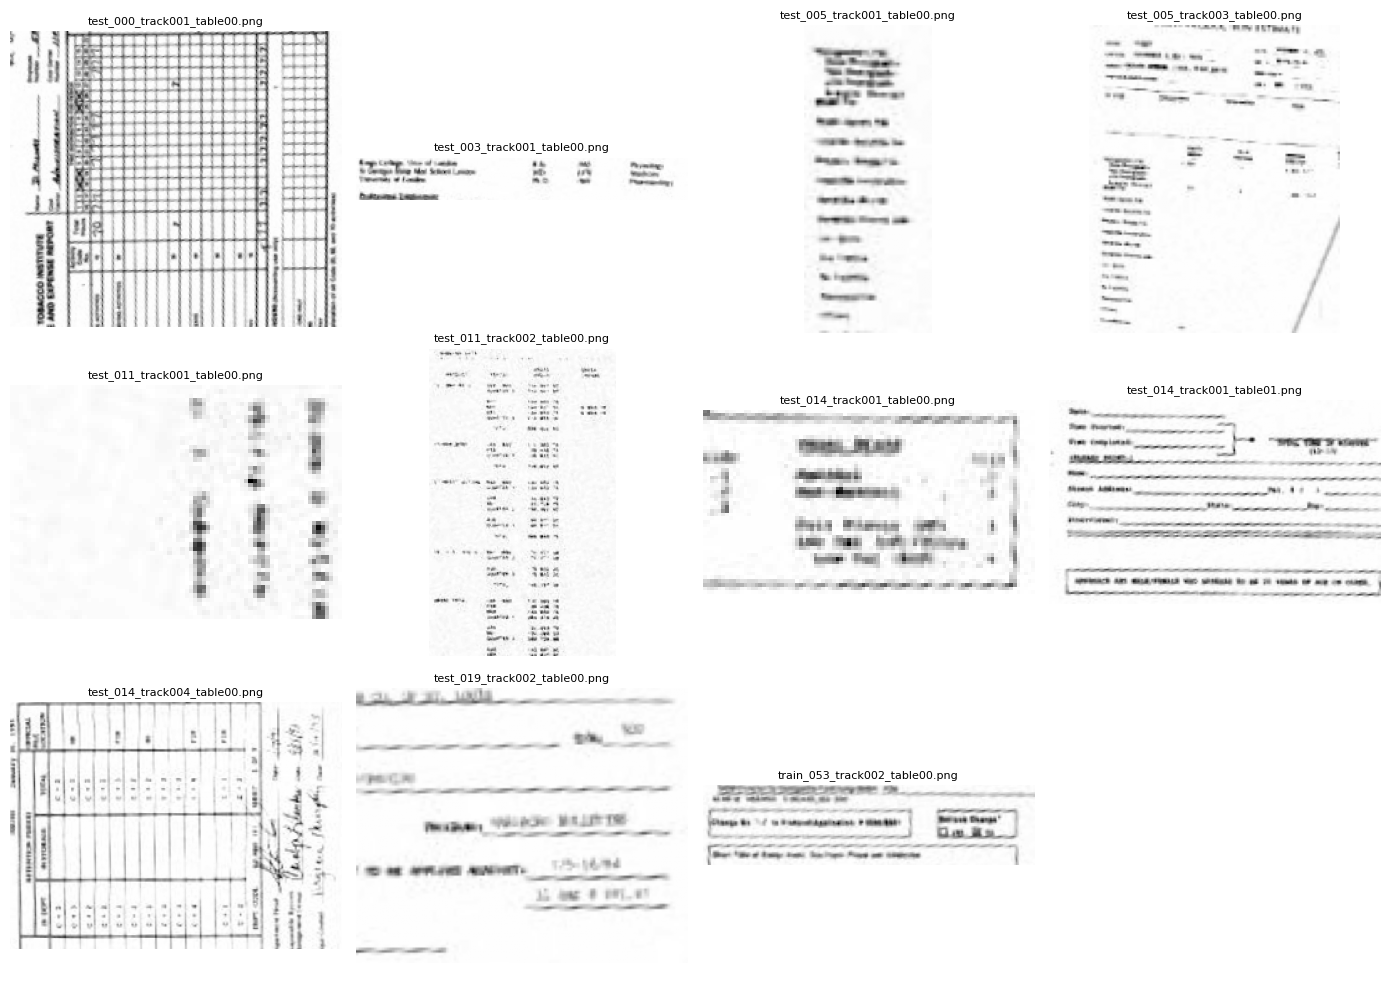

In [30]:
# --- Смотрим сохраненные таблицы (инфраструктура) ---
saved_tables = sorted(TABLE_OUTPUT_DIR.glob('*.png'))[:12]
if saved_tables:
    fig, axes = plt.subplots(3, 4, figsize=(14, 10))
    for axis, path in zip(axes.ravel(), saved_tables):
        image = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
        axis.imshow(image, cmap='gray')
        axis.axis('off')
        axis.set_title(path.name, fontsize=8)
    for axis in axes.ravel()[len(saved_tables):]:
        axis.axis('off')
    plt.tight_layout()
    plt.show()
else:
    print('Табличных фрагментов не сохранено')


### ✍️ Отчетная ячейка Шага 5

1. Можно ли доверять числу документов: на отложенных клипах разработки MAE равна 0.25, и точно посчитаны 6 из 8 клипов; обе ошибки дают лишний документ из-за разрывов треков, недосчёта не было.  
   На тестовых клипах ответов нет, скрытая проверка пропущена, и точность оценит преподаватель; итог 38 стоит считать верхней оценкой, поскольку трекер склонен к лишнему счёту.

2. Каков oracle-F1 и чем от него отличаются сквозные ошибки типов: oracle track-F1 на отложенной выборке равен 0.774 при точности 0.857; это верхняя граница при истинных рамках и треках, а в полном конвейере к ошибкам классификатора добавляются разрывы треков, неточное выпрямление по рамке детектора и смаз, поэтому сквозное качество ожидаемо ниже.  
   На тестовых клипах его не измерить; на клипе разработки train_053 найдены 3 документа из 3, и тип верен у двух (memo принят за letter), но это один клип.

3. Что даёт визуальная проверка таблиц: из 10 фрагментов на глаз примерно 3 являются целыми таблицами, причём два из них повёрнуты, а остальные представляют собой поля бланков, рамки с текстом и чек, часть размыта до нечитаемости.  
   Это не замена разметке: без масок таблиц на видео нельзя посчитать ни Dice, ни пропуски (ненайденные таблицы на вырезках не видны), а оценка на глаз по 10 фрагментам субъективна.

4. Что улучшить первым: дообучение U-Net на вырезках из видео, потому что целыми таблицами выглядят лишь около 3 из 10 фрагментов, это единственное звено без измеренного качества на видео, а разрыв доменов уже был виден в ДЗ 3 (Шаг 7, таблицы на 2 из 6 страниц заказчика); ошибка подсчёта при этом мала (MAE 0.25), поэтому трекер можно отложить.  
   План: разметить рамками таблиц от 100 до 200 выпрямленных лучших кадров из клипов обучающей части с предразметкой текущей U-Net, дообучить с весов ДЗ 3 с аугментациями под видео (смаз, перспектива, освещение, низкое разрешение), затем заново подобрать порог и впервые измерить Dice на клипах, не участвовавших в обучении; цена: несколько часов разметки и около 20 минут обучения, это дороже остальных вариантов.

## Шаг 6. Артефакты, README и сдача


In [31]:
# --- Манифест результатов (инфраструктура) ---
RESULTS = {
    'schema_version': 7,
    'seed': SEED,
    'device': device,
    'dataset': {
        'schema_version': manifest.get('schema_version'),
        'fingerprint': DATASET_FINGERPRINT,
        'fit_clips': len(FIT_CLIPS),
        'development_clips': len(DEVELOPMENT_CLIPS),
        'test_clips': len(TEST_CLIPS),
        'scenarios': SCENARIOS,
    },
    'detector': {
        'architecture': 'yolov8n',
        'epochs': DETECTOR_EPOCHS,
        'mAP50': round(DET_MAP50, 4),
        'mAP50_95': round(DET_MAP, 4),
        'train_clips': len(DETECTOR_TRAIN_CLIPS),
        'val_clips': len(DETECTOR_VAL_CLIPS),
        'keyframes_only': True,
    },
    'tracker': {
        **TRACKER_PARAMS,
        'calibration_MAE': round(TRACKER_CALIBRATION_MAE, 4),
        'holdout_MAE': round(TRACKER_HOLDOUT_MAE, 4),
        'holdout_exact_share': round(TRACKER_HOLDOUT_EXACT, 4),
        'holdout_by_scenario': tracker_holdout_results.to_dict(orient='records'),
    },
    'classifier_dz2': {
        'framework': DZ2_FRAMEWORK,
        'architecture': DZ2_ARCHITECTURE,
        'checkpoint': checkpoint_path.name,
        'config_source': DZ2_CONFIG_SOURCE,
        'preprocessing': DZ2_PREPROCESSING,
        'source': CLASSIFIER_SOURCE,
        'selection_reason': CLASSIFIER_SELECTION_REASON,
        'oracle_baseline_tuning_f1': round(ORACLE_BASELINE_TUNING['macro_f1'], 4),
        'oracle_baseline_tuning_log_loss': round(ORACLE_BASELINE_TUNING['log_loss'], 4),
        'oracle_baseline_holdout_f1': round(ORACLE_BASELINE_HOLDOUT['macro_f1'], 4),
        'oracle_baseline_holdout_log_loss': round(ORACLE_BASELINE_HOLDOUT['log_loss'], 4),
        'oracle_candidate_tuning_f1': (
            round(ORACLE_CANDIDATE_TUNING['macro_f1'], 4)
            if ORACLE_CANDIDATE_TUNING is not None else None
        ),
        'oracle_candidate_tuning_log_loss': (
            round(ORACLE_CANDIDATE_TUNING['log_loss'], 4)
            if ORACLE_CANDIDATE_TUNING is not None else None
        ),
        'oracle_candidate_holdout_f1': (
            round(ORACLE_CANDIDATE_HOLDOUT['macro_f1'], 4)
            if ORACLE_CANDIDATE_HOLDOUT is not None else None
        ),
        'oracle_selected_tuning_f1': round(ORACLE_SELECTED_TUNING['macro_f1'], 4),
        'oracle_selected_tuning_log_loss': round(ORACLE_SELECTED_TUNING['log_loss'], 4),
        'oracle_selected_holdout_f1': round(ORACLE_SELECTED_HOLDOUT['macro_f1'], 4),
        'oracle_selected_holdout_accuracy': round(ORACLE_SELECTED_HOLDOUT['accuracy'], 4),
        'oracle_selected_holdout_log_loss': round(ORACLE_SELECTED_HOLDOUT['log_loss'], 4),
    },
    'table_extractor_dz3': {
        'architecture': DZ3_ARCHITECTURE,
        'image_size': DZ3_IMG_SIZE,
        'threshold': DZ3_THRESHOLD,
        'config_source': DZ3_CONFIG_SOURCE,
        'trained_in_dz4': False,
        'source_metrics': metrics_dz3.get('final', {}),
    },
    'test_output': {
        'documents_predicted': int(answer['документов'].sum()),
        'table_fragments': int(answer['таблиц'].sum()),
        'clips': len(answer),
        'runtime_minutes': round(TEST_RUNTIME_MINUTES, 3),
        'teacher_document_MAE': TEACHER_TEST_MAE,
        'teacher_exact_share': TEACHER_TEST_EXACT,
        'teacher_type_count_MAE': TEACHER_TYPE_COUNT_MAE,
        'teacher_type_exact_share': TEACHER_TYPE_EXACT,
        'teacher_type_matched_documents': TEACHER_TYPE_MATCHED,
        'teacher_type_micro_precision': TEACHER_TYPE_MICRO_PRECISION,
        'teacher_type_micro_recall': TEACHER_TYPE_MICRO_RECALL,
        'teacher_type_micro_f1': TEACHER_TYPE_MICRO_F1,
    },
    'вывод_о_точности': 'заполните: development и hidden test, без подмены одной метрики другой',
    'вывод_о_таблицах': 'заполните: что видно на сохраненных фрагментах и чего нельзя доказать без масок',
    'что_улучшить': 'заполните: первое инженерное улучшение и ожидаемый эффект',
}
with open('/content/metrics_dz4.json', 'w', encoding='utf-8') as file:
    json.dump(RESULTS, file, ensure_ascii=False, indent=2)
print('=== СВОДКА ВАШЕЙ РАБОТЫ ===')
for key, value in RESULTS.items():
    print(' ', key, ':', value)


=== СВОДКА ВАШЕЙ РАБОТЫ ===
  schema_version : 7
  seed : 42
  device : cuda
  dataset : {'schema_version': 2, 'fingerprint': 'e06346a291e0', 'fit_clips': 48, 'development_clips': 16, 'test_clips': 20, 'scenarios': ['overlap_two', 'replacement_same_place', 'sequential_two', 'simultaneous_two', 'single_fast', 'single_gap', 'single_smooth', 'three_sequential']}
  detector : {'architecture': 'yolov8n', 'epochs': 16, 'mAP50': 0.995, 'mAP50_95': 0.9551, 'train_clips': 40, 'val_clips': 8, 'keyframes_only': True}
  tracker : {'detection_threshold': 0.35, 'min_affinity': 0.3, 'max_lost': 3, 'min_length': 4, 'appearance_gate': 0.7, 'calibration_MAE': 0.25, 'holdout_MAE': 0.25, 'holdout_exact_share': 0.75, 'holdout_by_scenario': [{'clip': 'train_053', 'scenario': 'three_sequential', 'truth': 3, 'prediction': 3, 'error': 0}, {'clip': 'train_054', 'scenario': 'replacement_same_place', 'truth': 2, 'prediction': 2, 'error': 0}, {'clip': 'train_056', 'scenario': 'overlap_two', 'truth': 2, 'prediction

In [32]:
# --- TODO 6.1: README ---
# Документ, по которому другой инженер поймет назначение, состав,
# разбиения, метрики каждого звена и ограничения без открытия notebook.
README = """
# Подсчёт, классификация документов и вырезка таблиц на видео (ДЗ 4)

## Назначение

Конвейер принимает видеоклип, в котором перед камерой проходят бумажные документы, и для каждого клипа возвращает:
1. число физических документов;
2. тип каждого документа (классы ДЗ 2);
3. вырезки таблиц с каждого документа.

Один физический документ соответствует одному треку: тип и вырезки выдаются один раз на трек, а не на каждый кадр.

## Состав конвейера

| Звено | Что делает | Откуда | Параметры |
|---|---|---|---|
| Детектор YOLO (yolov8n) | рамки листов на кадре | новое в ДЗ 4 | порог уверенности detection_threshold = 0.35, вход 640 |
| Признаки и трекер RobustDocumentTracker | связывает рамки в треки физических документов | новое в ДЗ 4 | min_affinity = 0.30, max_lost = 3, min_length = 4, appearance_gate = 0.70 |
| Геометрия | углы листа по рамке (find_document_quad), выпрямление (warp_document, длинная сторона 384) | новое в ДЗ 4 | углы упорядочены по полярному углу вокруг центра |
| Отбор кадров | оценка качества log(1 + дисперсия лапласиана) × log(1 + площадь листа), до 5 лучших кадров на трек | новое в ДЗ 4 | 5 кадров |
| Классификатор | тип документа, среднее вероятностей по 5 лучшим кадрам трека | ДЗ 2 (classifier.pt), адаптирован в ДЗ 4 | ResNet-18, 224×224, серое ×3, нормализация ImageNet |
| U-Net | области таблиц на одном лучшем кадре трека | ДЗ 3 (table_extractor.pt, model_config.json) | 14.3 млн параметров, вход 384×384, порог 0.35 |

ДЗ 1 используется косвенно: на его очищенных данных и разбиении обучен классификатор ДЗ 2.

Адаптация классификатора к видео: старт с весов ДЗ 2, разморожены голова fc (скорость обучения 2e-4) и блок layer4 (1e-5) вместе с его BatchNorm; остальной энкодер заморожен, его BatchNorm работают в режиме eval. Прошло 4 эпохи, выбрана первая. Выбор между исходной и адаптированной моделью делался только по настроечной выборке.

## Артефакты (dz4_artifacts.zip)

| Файл | Содержимое |
|---|---|
| detector.pt | веса детектора YOLO (yolov8n, лучшая эпоха 8) |
| classifier_dz2.pt, classifier_config.json | выбранный классификатор (ДЗ 2 + адаптация к видео) и контракт предобработки |
| table_extractor_dz3.pt, table_extractor_config.json | U-Net ДЗ 3 без дообучения, порог и постобработка |
| metrics_dz4.json, metrics_dz2_source.json, metrics_dz3_source.json | метрики ДЗ 4 и исходные метрики ДЗ 2 и ДЗ 3 |
| answer.csv | прогноз по 20 test-клипам: документы, типы, таблицы, мс на кадр |
| tracker_grid.csv, tracker_calibration_predictions.csv, tracker_holdout_predictions.csv | сетка подбора трекера и его прогнозы |
| classifier_adaptation_history.csv | история адаптации классификатора по эпохам |
| tables_sample/ | до 30 вырезок таблиц (клип_trackNNN_tableNN.png); файл train_053_… — пробный запуск на клипе разработки, а не test |
| artifact_manifest.json, requirements.txt | состав архива и версии библиотек |

## Данные и разбиения

Все разбиения групповые, по клипу: кадры одного клипа и одного трека не попадают в разные части, потому что соседние кадры почти дублируют друг друга.

| Часть | Для чего | Объём |
|---|---|---|
| обучение детектора | обучение YOLO | 40 клипов fit: 840 ключевых кадров, 760 листов |
| проверка детектора | ранняя остановка и mAP | 8 клипов fit: 168 ключевых кадров, 152 листа |
| fit | адаптация классификатора | 48 клипов, 82 документа, до 6 кадров на трек |
| настроечная (tuning) | выбор эпохи, выбор исходной или адаптированной модели, параметры трекера | 8 клипов разработки, 14 документов |
| отложенная (holdout) | однократная итоговая оценка | 8 клипов разработки, 14 документов |
| test | итоговый прогноз, ответов нет | 20 клипов, 800 кадров |

## Метрики по звеньям

| Звено | Метрика | Значение | Где измерено |
|---|---|---|---|
| Детектор | mAP50 / mAP50-95 по кадрам | 0.995 / 0.955 | проверка детектора: 8 клипов fit, 168 ключевых кадров |
| Трекер и подсчёт | MAE числа документов | 0.25, точно в 6 из 8 клипов, обе ошибки дают лишний документ | отложенные клипы |
| Классификатор, oracle | macro-F1 по трекам / точность | 0.774 / 0.857 (12 из 14) | отложенная выборка, истинные углы и треки |
| Классификатор, oracle | macro-F1 по трекам | исходная 0.783, адаптированная 0.933 (оценка оптимистична) | настроечная выборка |
| Классификатор, сквозной | доля верных типов | не измерен; пример: 2 из 3 на клипе train_053 | клип разработки |
| U-Net | Dice / IoU | Dice 0.931 по всем страницам, 0.872 на страницах с таблицами, IoU 0.826 | сканы подрядчика, валидация ДЗ 3 |
| U-Net | визуальная проверка | около 3 из 10 вырезок являются целыми таблицами | test-видео, на глаз |
| Скорость | мс на кадр | около 15 (около 65 кадров в секунду): детектор 12.4, трекер 0.2, геометрия 2.4 | клип train_053, GPU L4 |
| Скорость | мс на клип в конце | классификатор и U-Net: 110 мс на 3 документа | клип train_053, GPU L4 |

Итог на test: 38 документов и 10 вырезок таблиц. Число документов — верхняя оценка, потому что трекер склонен к лишнему счёту.

## Ограничения

1. Качество U-Net на видео не измерено: разметки таблиц на видео нет, а метрики ДЗ 3 относятся к сканам подрядчика. Уже на сканах заказчика (ДЗ 3, Шаг 7) таблицы нашлись лишь на 2 из 6 страниц.
2. Oracle-оценка классификатора является верхней границей. Сквозное качество с рамками детектора и треками трекера не измерено.
3. Отложенная выборка мала: одна ошибка меняет точность примерно на 7 п. п.
4. Рост на настроечной выборке после адаптации оптимистичен: по ней же выбирались эпоха и модель. На отложенной выборке адаптация ничего не изменила.
5. При быстром движении и перекрытии треки рвутся, и документ считается дважды.
6. Ориентация листа не исправляется: повёрнутый лист попадает в классификатор и U-Net повёрнутым, вырезанные таблицы тоже бывают повёрнуты.
7. Таблицы вырезаются из выпрямленного листа с длинной стороной 384, поэтому мелкий текст бывает нечитаемым.
8. Скорость замерена на одном клипе, на GPU L4, с чтением кадров с диска; классификатор и U-Net в покадровое время не входят.

## Запуск

result = run_clip(clip, split='train' или 'test', save_tables=True)

Результат: словарь с полями documents (число документов), types (типы и их число), tables (число вырезок), records (тип, уверенность и число таблиц по каждому треку), frames, detections, mean_ms_per_frame.

## Что улучшить первым

Дообучить U-Net на вырезках из видео: разметить рамками таблиц от 100 до 200 выпрямленных лучших кадров из клипов fit с предразметкой текущей моделью, дообучить с весов ДЗ 3 с аугментациями под видео (смаз, перспектива, освещение, низкое разрешение), заново подобрать порог и впервые измерить Dice на клипах, не участвовавших в обучении.

## Использование ИИ

Структуру и оформление этого README (разделы и таблицы) помогал составить ИИ-ассистент. Числа взяты из выводов ноутбука и сверены с ними.
""".strip() + '\n'
Path('/content/README.md').write_text(README, encoding='utf-8')
print(README)

# Подсчёт, классификация документов и вырезка таблиц на видео (ДЗ 4)

## Назначение

Конвейер принимает видеоклип, в котором перед камерой проходят бумажные документы, и для каждого клипа возвращает:
1. число физических документов;
2. тип каждого документа (классы ДЗ 2);
3. вырезки таблиц с каждого документа.

Один физический документ соответствует одному треку: тип и вырезки выдаются один раз на трек, а не на каждый кадр.

## Состав конвейера

| Звено | Что делает | Откуда | Параметры |
|---|---|---|---|
| Детектор YOLO (yolov8n) | рамки листов на кадре | новое в ДЗ 4 | порог уверенности detection_threshold = 0.35, вход 640 |
| Признаки и трекер RobustDocumentTracker | связывает рамки в треки физических документов | новое в ДЗ 4 | min_affinity = 0.30, max_lost = 3, min_length = 4, appearance_gate = 0.70 |
| Геометрия | углы листа по рамке (find_document_quad), выпрямление (warp_document, длинная сторона 384) | новое в ДЗ 4 | углы упорядочены по полярному углу вокруг центра |
| Отбор к

In [33]:
# --- Упаковка dz4_artifacts.zip (инфраструктура) ---
ART = Path('/content/dz4_artifacts')
shutil.rmtree(ART, ignore_errors=True)
ART.mkdir()

shutil.copy(DETECTOR_WEIGHTS, ART / 'detector.pt')
torch.save({'state_dict': classifier.state_dict(), 'config': DZ2_MODEL_CONFIG}, ART / 'classifier_dz2.pt')
with open(ART / 'classifier_config.json', 'w', encoding='utf-8') as file:
    json.dump(DZ2_MODEL_CONFIG, file, ensure_ascii=False, indent=2)
shutil.copy(DZ2 / 'metrics.json', ART / 'metrics_dz2_source.json')

torch.save({'state_dict': table_model.state_dict(), 'config': DZ3_MODEL_CONFIG}, ART / 'table_extractor_dz3.pt')
with open(ART / 'table_extractor_config.json', 'w', encoding='utf-8') as file:
    json.dump(DZ3_MODEL_CONFIG, file, ensure_ascii=False, indent=2)
shutil.copy(DZ3 / 'metrics_dz3.json', ART / 'metrics_dz3_source.json')

shutil.copy('/content/metrics_dz4.json', ART / 'metrics_dz4.json')
shutil.copy('/content/README.md', ART / 'README.md')
answer.to_csv(ART / 'answer.csv', index=False)
tracker_grid.to_csv(ART / 'tracker_grid.csv', index=False)
tracker_calibration_results.to_csv(ART / 'tracker_calibration_predictions.csv', index=False)
tracker_holdout_results.to_csv(ART / 'tracker_holdout_predictions.csv', index=False)
CLASSIFIER_HISTORY.to_csv(ART / 'classifier_adaptation_history.csv', index=False)

tables_sample = ART / 'tables_sample'
tables_sample.mkdir()
for path in sorted(TABLE_OUTPUT_DIR.glob('*.png'))[:30]:
    shutil.copy(path, tables_sample / path.name)

artifact_manifest = {
    'schema_version': 7,
    'task': 'video_document_pipeline',
    'inputs': ['video frames'],
    'components': {
        'detector': 'detector.pt',
        'classifier': 'classifier_dz2.pt',
        'table_extractor': 'table_extractor_dz3.pt',
    },
    'config': {
        'tracker': TRACKER_PARAMS,
        'classes': DZ2_CLASSES,
        'frame_size': manifest['frame_size'],
        'dataset_fingerprint': DATASET_FINGERPRINT,
    },
}
with open(ART / 'artifact_manifest.json', 'w', encoding='utf-8') as file:
    json.dump(artifact_manifest, file, ensure_ascii=False, indent=2)

with open(ART / 'requirements.txt', 'w', encoding='utf-8') as file:
    file.write('ultralytics==8.4.117\n')
    file.write('segmentation-models-pytorch==0.3.4\n')
    file.write('timm==' + timm.__version__ + '\n')
    file.write('torch==' + torch.__version__.split('+')[0] + '\n')
    file.write('torchvision==' + torchvision.__version__.split('+')[0] + '\n')
    file.write('opencv-python==' + cv2.__version__ + '\n')
    file.write('scipy==' + scipy.__version__ + '\n')
    file.write('scikit-learn==' + sklearn.__version__ + '\n')
    file.write('numpy==' + np.__version__ + '\n')
    file.write('pandas==' + pd.__version__ + '\n')

zip_path = shutil.make_archive('/content/dz4_artifacts', 'zip', ART)
print(f'готово: {zip_path} ({Path(zip_path).stat().st_size / 1024**2:.1f} МБ)')
print('содержимое:', sorted(path.name for path in ART.iterdir()))

try:
    from google.colab import files
    files.download(zip_path)
except Exception:
    pass


готово: /content/dz4_artifacts.zip (96.1 МБ)
содержимое: ['README.md', 'answer.csv', 'artifact_manifest.json', 'classifier_adaptation_history.csv', 'classifier_config.json', 'classifier_dz2.pt', 'detector.pt', 'metrics_dz2_source.json', 'metrics_dz3_source.json', 'metrics_dz4.json', 'requirements.txt', 'table_extractor_config.json', 'table_extractor_dz3.pt', 'tables_sample', 'tracker_calibration_predictions.csv', 'tracker_grid.csv', 'tracker_holdout_predictions.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Шаг 7. Рефлексия и сдача

### Перед сдачей

1. Выполните «Среда выполнения → Перезапустить и выполнить все».
2. Убедитесь, что все `TODO` заполнены и все самопроверки пройдены.
3. Заполните отчетные ячейки своими словами и числами.
4. Скачайте `dz4_artifacts.zip`.

### Файлы для сдачи

- `ФамилияИО_КонвейерНаПотоке.2026_Модуль4_ДЗ.ipynb`;
- `ФамилияИО_КонвейерНаПотоке.2026_Модуль4_Метрики.json` (`metrics_dz4.json`);
- рефлексия по правилам курса.

На мини-защите нужно уметь отдельно объяснить: почему детектор, трекер и классификатор имеют разные метрики; где использованы ДЗ 1–3; почему hidden test нельзя использовать для настройки параметров.
